# **CS781 Assignment 3 — Decoder-Only Transformer Language Models** [1000 Marks]

## Enter your details

**Full Name:** _Your name_  
**Roll Number:** _Your roll number_  
**IITK Email:** _Your email_  
**Deadline:** Refer to the deadline announced on Hello IITK / the course forum.

> Submit one ZIP named `CS781-A3-[Firstname]-[Lastname]-[RollNo].zip`.

> Download the autograders and additional files: [https://drive.google.com/drive/folders/1i23BA98WeCFCqGi9UI25ZbG02D-l669-?usp=sharing](https://drive.google.com/drive/folders/1i23BA98WeCFCqGi9UI25ZbG02D-l669-?usp=sharing)

In [27]:

import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Number of GPUs:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

assert torch.cuda.device_count() == 2, (
    "This training configuration requires two GPUs."
)


PyTorch version: 2.10.0+cu128
CUDA available: True
Number of GPUs: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


In [28]:

from pathlib import Path

# Find all attached input files
root = Path("/kaggle/input")

print("ATTACHED DATASETS:")
for item in root.iterdir():
    print(item)

print("\nSEARCHING FOR ASSIGNMENT FILES:")

required = [
    "a1_tokenizer.py",
    "common.py",
    "common_grading.py",
    "download_data.py",
    "autograder_q1.py",
    "requirements.txt",
]

for filename in required:
    matches = list(root.rglob(filename))

    if matches:
        print(f"FOUND: {filename}")
        for path in matches:
            print("  ", path)
    else:
        print(f"MISSING: {filename}")


ATTACHED DATASETS:
/kaggle/input/datasets

SEARCHING FOR ASSIGNMENT FILES:
FOUND: a1_tokenizer.py
   /kaggle/input/datasets/palakmeena0304/cs781-a3-support-files/cs781-a3-support-files/a1_tokenizer.py
FOUND: common.py
   /kaggle/input/datasets/palakmeena0304/cs781-a3-support-files/cs781-a3-support-files/common.py
FOUND: common_grading.py
   /kaggle/input/datasets/palakmeena0304/cs781-a3-support-files/cs781-a3-support-files/common_grading.py
FOUND: download_data.py
   /kaggle/input/datasets/palakmeena0304/cs781-a3-support-files/cs781-a3-support-files/download_data.py
FOUND: autograder_q1.py
   /kaggle/input/datasets/palakmeena0304/cs781-a3-support-files/cs781-a3-support-files/autograder_q1.py
FOUND: requirements.txt
   /kaggle/input/datasets/palakmeena0304/cs781-a3-support-files/cs781-a3-support-files/requirements.txt


In [29]:

from pathlib import Path

SUPPORT_DIR = Path(
    "/kaggle/input/datasets/palakmeena0304/"
    "cs781-a3-support-files/cs781-a3-support-files"
)

assert SUPPORT_DIR.is_dir(), "Support directory not found!"

print("Support directory:", SUPPORT_DIR)
print("\nAvailable files:")

for file in sorted(SUPPORT_DIR.iterdir()):
    print(file.name)


Support directory: /kaggle/input/datasets/palakmeena0304/cs781-a3-support-files/cs781-a3-support-files

Available files:
a1_tokenizer.py
autograder_q1.py
autograder_q2.py
autograder_q3.py
autograder_q4.py
autograder_q5.py
common.py
common_grading.py
download_data.py
make_submission.ps1
make_submission.sh
requirements.txt


# Marking overview [1000 Marks]

| Question | Topic | Marks |
|---|---|---:|
| Q1 | Decoder-only Transformer from scratch | 220 |
| Q2 | MHA, GQA, MQA, and MLA (Q2 only) | 170 |
| Q3 | Rotary positional embeddings | 180 |
| Q4 | SGD, RMSProp, AdamW, and Muon | 210 |
| Q5 | PyTorch built-ins and head-to-head comparison | 180 |
| Final synthesis | Cross-question synthesis | 40 |
| **Total** |  | **1000** |



# Assignment overview

**Corpus:** the seven-book course corpus prepared automatically by `download_data.py` into `data/raw/` <br>
**Budget:** every model you train in this assignment must have **≤ 50M parameters**.
This is not a limitation to fight against — it's the point of the assignment. With a
fixed, small parameter budget, the interesting question stops being "how big can I make
this?" and becomes "what architectural and optimization choices actually matter?" You
will spend this assignment answering that question five different ways.

> In the below cells you'll find configurations to tune the hyperparameters to get models of various sizes. We expect all the models to be under 50M parameters. The default hyperparameters generate models of **66K** and **5M** parameters when the **`SMOKE_TEST`** is **`True`** or **`False`** respectively.

## What you're building

You'll implement a GPT-style decoder-only Transformer **from raw PyTorch tensor
operations** (`torch.matmul`, `torch.softmax`, etc.) — explicitly *not* using
`torch.nn.Transformer`, `nn.TransformerEncoderLayer`, or `nn.MultiheadAttention` — and
train it with next-token prediction on Harry Potter text using the BPE tokenizer you
built in A-1. Across five questions, you'll swap out one architectural or optimization
component at a time (attention pattern, positional encoding, optimizer) and hold
everything else fixed, which is the only way to know *why* a change in perplexity
happened. In the final question, you'll rebuild the same three ablations using PyTorch's
built-in Transformer modules and compare against your from-scratch versions — both for
correctness (do they roughly agree?) and for practical differences (speed, memory, code
complexity).

## How this notebook is organized

Each of the 5 questions below follows the same pattern:
1. **Intro** — the concept, why it matters, what you'll observe.
2. **Code stub** — a `%%writefile` cell that saves your implementation to a `.py` file
   (this is required — the autograder imports these files directly, it does not re-run
   your notebook). Fill in every `# TODO`.
3. **AutoGraders and helper zips** — Please download the additional zip files and autograder scripts from [https://drive.google.com/drive/folders/1i23BA98WeCFCqGi9UI25ZbG02D-l669-?usp=sharing](https://drive.google.com/drive/folders/1i23BA98WeCFCqGi9UI25ZbG02D-l669-?usp=sharing)
3. **Analysis & discovery questions** — run experiments and write up what you find.
   These are not busywork: several of them don't have a "textbook" answer, and your
   observations on *this specific corpus, at this specific scale* are the deliverable.
4. **Deliverable cell** — saves your trained checkpoint + config + metrics in the format
   the autograder expects.


## Step-count helpers for experiments

`TRAIN_STEPS` and `OPT_STEPS` are **convenience defaults only**.

`SMOKE_TEST = True` is only for pipeline validation; its tiny defaults are not intended
as final experimental results.


## Submission ZIP Structure

Submit one ZIP file named: `CS781-A3-[Firstname]-[Lastname]-[RollNo].zip`.

Replace the bracketed fields with your details.

### 1. Save your notebook

Save or download your completed notebook as **`notebook.ipynb`**, retaining
all available outputs, plots, experiment results, and written explanations.

For a partial submission, include the same notebook with your attempted work.
Do not clear its outputs before submitting.

### 2. Arrange the submission files

A full submission should have the following structure:

```text
CS781-A3-Firstname-Lastname-RollNo.zip
    notebook.ipynb
    a1_tokenizer.py
    attention.py
    model_arch.py
    rope.py
    optim_muon.py
    model_builtin.py
    common.py
    analysis_log.json
    requirements.txt
    download_data.py
    decoder.svg
    submissions/
        q1/
            model.pt
            config.json
            metrics.json
            [saved Python source files]
        q2/
            model.pt
            config.json
            metrics.json
            [saved Python source files]
        q3/
            model.pt
            config.json
            metrics.json
            [saved Python source files]
        q4/
            model.pt
            config.json
            metrics.json
            [saved Python source files]
        q5/
            model.pt
            config.json
            metrics.json
            [saved Python source files]
```

The files and `submissions/` directory must be **directly inside the ZIP**,
without an additional enclosing folder.

`[saved Python source files]` is a placeholder in the illustration above.
Keep the actual files generated by each question's save cell.

You may optionally use the `make_submission.sh` or `make_submission.ps1` script in the "Student Package" to zip everything.

### 3. Preserve question-specific source files

Include each saved question folder **as generated**. The main source files
required within these folders are:

| Question folder | Main Python source files |
|---|---|
| `submissions/q1/` | `attention.py`, `model_arch.py` |
| `submissions/q2/` | `attention.py`, `model_arch.py` |
| `submissions/q3/` | `attention.py`, `model_arch.py`, `rope.py` |
| `submissions/q4/` | `attention.py`, `model_arch.py`, `optim_muon.py`, and `rope.py` if used |
| `submissions/q5/` | `model_builtin.py` |

Retain other source files copied into these folders, including tokenizer files
and imported dependencies.

**Do not replace earlier question snapshots with the final root-level Python
files.** Later questions may change the implementation, while each checkpoint
must remain paired with the source code used to create it.

### 4. Partial submissions

Partial submissions use the **same ZIP filename and directory layout**.

- Include `notebook.ipynb` with all attempted work and available evidence.
- Include all implemented Python files and existing question folders.
- Keep available files from incomplete question folders, even if a checkpoint
  or some metrics have not yet been produced.
- You may omit files and question folders that have not been generated.
- Do not create dummy checkpoints, empty metric files, or fabricated results.
- State clearly in the notebook which questions or subtasks are incomplete.
- **Q5 dependency:** Even for a partial submission, include your implemented Q1 attention source at `submissions/q1/attention.py` and any dependencies it imports. The Q5 autograder uses it for the numerical-equivalence check. A Q1 checkpoint is not required for this check.


Partial submission does not waive the requirements of the subtasks attempted.
Missing artifacts may prevent the corresponding autograder checks from running.


# Section 0 — Setup

Run this once. It installs the light dependencies (`tokenizers` is used only as a fallback when the required A-1 tokenizer hook is missing
or unusable — see the tokenizer cell below) and pulls in `common.py`, which is shared infrastructure: data loading,
the held-out sentence sampler, `perplexity_of_texts`, and `save_submission`. Everyone
— students, the solution notebook, and the autograder — uses the exact same
`common.py`, so the course-defined perplexity convention is applied consistently. Do not
modify `common.py`.


In [31]:
# Student-added bootstrap: locate the complete Assignment-3 package in Colab/Kaggle.
# This cell uses only the Python standard library so it can run before common.py exists.
import os as _bootstrap_os
import shutil as _bootstrap_shutil
from pathlib import Path as _BootstrapPath

_A3_PROJECT_ROOT = _BootstrapPath.cwd().resolve()
if not (_A3_PROJECT_ROOT / "common.py").is_file():
    _direct_candidates = [
        _BootstrapPath("/content/assignment_3"),
        _BootstrapPath("/kaggle/working/assignment_3"),
        _BootstrapPath("/kaggle/working"),
    ]
    _source_candidates = [
        p.resolve() for p in _direct_candidates
        if (p / "common.py").is_file() and (p / "download_data.py").is_file()
    ]
    _kaggle_input = _BootstrapPath("/kaggle/input")
    if not _source_candidates and _kaggle_input.is_dir():
        _source_candidates = sorted({
            p.parent.resolve() for p in _kaggle_input.rglob("common.py")
            if (p.parent / "download_data.py").is_file()
        })
    if len(_source_candidates) > 1:
        raise RuntimeError(
            "Multiple Assignment-3 support packages were found. Keep one attached package "
            f"or start the notebook inside the intended folder: {_source_candidates}"
        )
    if len(_source_candidates) == 1:
        _source_root = _source_candidates[0]
        if str(_source_root).startswith("/kaggle/input/"):
            _writable_root = _BootstrapPath("/kaggle/working/assignment_3")
            _bootstrap_shutil.copytree(_source_root, _writable_root, dirs_exist_ok=True)
            _A3_PROJECT_ROOT = _writable_root.resolve()
        else:
            _A3_PROJECT_ROOT = _source_root
        _bootstrap_os.chdir(_A3_PROJECT_ROOT)

print("Assignment-3 project root:", _BootstrapPath.cwd().resolve())


Assignment-3 project root: /kaggle/working/assignment_3


In [32]:

# ============================================
# HUGGING FACE AUTHENTICATION FOR KAGGLE
# ============================================

import os
import sys
import subprocess

from kaggle_secrets import UserSecretsClient

# Read token securely from Kaggle Secrets
secrets = UserSecretsClient()
hf_token = secrets.get_secret("HF_TOKEN")

assert hf_token, (
    "HF_TOKEN not found. "
    "Add HF_TOKEN in Kaggle Secrets and enable access."
)

# Make token available to download_data.py
os.environ["HF_TOKEN"] = hf_token

# Install the Hugging Face client if necessary
subprocess.run(
    [sys.executable, "-m", "pip", "-q",
     "install", "huggingface_hub"],
    check=True
)

from huggingface_hub import login, whoami

login(
    token=hf_token,
    add_to_git_credential=False
)

account = whoami(token=hf_token)

print("Hugging Face authentication successful.")
print("Account:", account["name"])
print("HF_TOKEN environment variable configured.")


Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face authentication successful.
Account: Anirudh-3810
HF_TOKEN environment variable configured.


In [33]:

from huggingface_hub import HfApi

api = HfApi()

repo_id = "Exploration-Lab/CS781"

try:
    files = api.list_repo_files(
        repo_id=repo_id,
        repo_type="dataset",
        token=os.environ["HF_TOKEN"]
    )

    assignment_files = [
        f for f in files
        if "Assignment-3" in f
    ]

    print("Repository access: SUCCESS")
    print("Assignment 3 files:", len(assignment_files))

    for filename in assignment_files:
        print(filename)

except Exception as exc:
    print("Repository access failed.")
    print(type(exc).__name__, str(exc)[:500])
    raise


Repository access: SUCCESS
Assignment 3 files: 7
Assignment-3/test/Harry Potter-Book 7-The Deathly Hallows.txt
Assignment-3/train/Harry Potter-Book 1-The Sorcerers Stone.txt
Assignment-3/train/Harry Potter-Book 2-The Chamber of Secrets.txt
Assignment-3/train/Harry Potter-Book 3-The Goblet of Fire.txt
Assignment-3/train/Harry Potter-Book 4-The Prisoner of Azkaban.txt
Assignment-3/train/Harry Potter-Book 5-The Order of the Phoenix.txt
Assignment-3/validation/Harry Potter-Book 6-The Half-Blood Prince.txt


In [34]:
import sys, os, time, json, math, random, subprocess, importlib.util
from pathlib import Path

# Colab starts in /content even when a notebook is opened from elsewhere. If the
# assignment folder was unzipped there, enter it automatically.
if not Path("common.py").is_file():
    colab_project = Path("/content/assignment_3")
    if colab_project.joinpath("common.py").is_file():
        os.chdir(colab_project)
if not Path("common.py").is_file():
    raise FileNotFoundError(
        "Assignment support files were not found. Upload/unzip the complete "
        "assignment_3 folder in /content, then run this notebook again."
    )

# Colab normally includes PyTorch. Install only the two lightweight dependencies used
# for the fallback tokenizer and the course-approved dataset download.
for package in ("tokenizers", "huggingface_hub"):
    if importlib.util.find_spec(package) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

sys.path.insert(0, os.path.abspath("."))

# Download and normalize the seven books once. Subsequent runs reuse data/raw/.
raw_dir = Path("data/raw")
if len(list(raw_dir.glob("book*.txt"))) != 7:
    subprocess.run([sys.executable, "download_data.py", "--raw-dir", str(raw_dir)], check=True)

import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from common import (
    load_corpus, held_out_sentences, remove_sentences_from_text,
    BPETokenizerWrapper, load_a1_tokenizer_or_fallback, TokenDataset, perplexity_of_texts,
    count_parameters, assert_within_budget, save_submission, MAX_PARAMS, SEED,
)

def reset_seed(seed=SEED):
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

reset_seed()
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("device:", device, "| param budget:", f"{MAX_PARAMS:,}")

# Colab-friendly validation mode. Leave this True for a quick Run-all smoke test.
# Set it to False before collecting the full training curves used in a submission.
SMOKE_TEST = False  # @param {type:"boolean"}
MODEL_DIM = 64 if SMOKE_TEST else 256
MODEL_LAYERS = 1 if SMOKE_TEST else 4
MODEL_FF = 128 if SMOKE_TEST else 1024
MODEL_SEQ_LEN = 64 if SMOKE_TEST else 256
TRAIN_BATCH_SIZE = 2 if SMOKE_TEST else 32
# Convenience defaults only: these are not grading caps or required exact counts.
TRAIN_STEPS = 1 if SMOKE_TEST else 500
OPT_STEPS = 1 if SMOKE_TEST else 400
TOKENIZER_VOCAB_SIZE = 512 if SMOKE_TEST else 8000
print("mode:", "SMOKE TEST" if SMOKE_TEST else "FULL TRAINING")

os.makedirs("submissions", exist_ok=True)
ANALYSIS_LOG_PATH = "analysis_log.json"
def log_result(key, value):
    log = json.load(open(ANALYSIS_LOG_PATH)) if os.path.exists(ANALYSIS_LOG_PATH) else {}
    log[key] = value
    json.dump(log, open(ANALYSIS_LOG_PATH, "w"), indent=2)
    print(f"[logged] {key} = {value}")


device: cuda | param budget: 50,000,000
mode: FULL TRAINING


In [35]:
# Optional crash/cross-account recovery bootstrap.
# Set this to an exact attached ZIP when more than one non-identical candidate is present.
Q1_RECOVERY_ARCHIVE = None  # e.g. "/kaggle/input/my-a3-q1/q1_all_artifacts.zip"

import hashlib as _recovery_hashlib
import tempfile as _recovery_tempfile
import zipfile as _recovery_zipfile
import shutil as _recovery_shutil

def _recovery_sha256(path, chunk_size=1024 * 1024):
    digest = _recovery_hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()

def _discover_q1_archives(explicit=None):
    if explicit:
        path = Path(explicit).expanduser().resolve()
        if not path.is_file():
            raise FileNotFoundError(f"Configured Q1 recovery archive does not exist: {path}")
        return [path]
    names = {"q1_all_artifacts.zip", "q1_smoke_all_artifacts.zip"}
    roots = [Path.cwd(), Path("/kaggle/working"), Path("/kaggle/input")]
    candidates = []
    for root in roots:
        if not root.is_dir():
            continue
        for name in names:
            candidates.extend(root.rglob(name) if root.name == "input" else root.glob(name))
    unique = {}
    for path in candidates:
        if path.is_file():
            unique.setdefault(_recovery_sha256(path), path.resolve())
    return sorted(unique.values(), key=lambda p: str(p))

def _restore_q1_archive(archive_path, destination=None):
    archive_path = Path(archive_path).resolve()
    destination = Path(destination or Path.cwd()).resolve()
    with _recovery_zipfile.ZipFile(archive_path) as archive:
        bad = archive.testzip()
        if bad is not None:
            raise ValueError(f"Corrupt Q1 recovery ZIP member: {bad}")
        names = set(archive.namelist())
        manifest_name = "recovery/integrity_manifest.json"
        if manifest_name not in names:
            raise ValueError("Recovery ZIP has no integrity manifest.")
        manifest = json.loads(archive.read(manifest_name).decode("utf-8"))
        if "notebook_snapshot_sha256" in manifest:
            snapshot = archive.read("recovery/notebook_snapshot.ipynb")
            if _recovery_hashlib.sha256(snapshot).hexdigest() != manifest["notebook_snapshot_sha256"]:
                raise ValueError("Notebook snapshot checksum mismatch")
            print("Verified optional notebook snapshot inside the archive; export it separately if needed.")
        with _recovery_tempfile.TemporaryDirectory(prefix="a3_q1_restore_") as tmp:
            tmp_root = Path(tmp).resolve()
            for member in archive.infolist():
                if member.is_dir() or member.filename.startswith("recovery/"):
                    continue
                target = (tmp_root / member.filename).resolve()
                if tmp_root not in target.parents:
                    raise ValueError(f"Unsafe path in recovery ZIP: {member.filename}")
                target.parent.mkdir(parents=True, exist_ok=True)
                with archive.open(member) as source, open(target, "wb") as sink:
                    _recovery_shutil.copyfileobj(source, sink)
            for rel, info in manifest.get("files", {}).items():
                restored = tmp_root / rel
                if not restored.is_file():
                    raise ValueError(f"Manifest member is missing: {rel}")
                if restored.stat().st_size != int(info["size"]):
                    raise ValueError(f"Size mismatch while restoring {rel}")
                if _recovery_sha256(restored) != info["sha256"]:
                    raise ValueError(f"Checksum mismatch while restoring {rel}")
            conflicts = []
            for rel in manifest.get("files", {}):
                incoming, current = tmp_root / rel, destination / rel
                if current.is_file() and _recovery_sha256(current) != _recovery_sha256(incoming):
                    conflicts.append(rel)
            if conflicts:
                raise RuntimeError(
                    "Recovery would overwrite non-identical current work. Resolve or explicitly "
                    f"move these files first: {conflicts[:20]}"
                )
            for rel in manifest.get("files", {}):
                incoming, current = tmp_root / rel, destination / rel
                if not current.exists():
                    current.parent.mkdir(parents=True, exist_ok=True)
                    _recovery_shutil.copy2(incoming, current)
    print("Restored and checksum-validated Q1 archive:", archive_path)

_q1_archive_candidates = _discover_q1_archives(Q1_RECOVERY_ARCHIVE)
if len(_q1_archive_candidates) == 1:
    _restore_q1_archive(_q1_archive_candidates[0])
elif len(_q1_archive_candidates) > 1:
    print("Multiple non-identical Q1 recovery archives found; set Q1_RECOVERY_ARCHIVE explicitly:")
    for _candidate in _q1_archive_candidates:
        print(" -", _candidate)
else:
    print("No Q1 recovery archive selected; starting from current local artifacts.")


Restored and checksum-validated Q1 archive: /kaggle/working/q1_smoke_all_artifacts.zip


## 0.1 Data: loading Harry Potter and carving out a held-out set

`load_corpus` concatenates every `.txt` file under `data/raw/` (see `data/README.md`
if that directory is empty) and splits it into chapters. `held_out_sentences` then
samples a fixed set of sentences from **5 intermediate chapters** — deliberately
avoiding the first/last 15% of chapters, which read differently (scene-setting /
wrap-up) than the bulk of the narrative — and `remove_sentences_from_text` deletes
those exact sentences from the training text so you're not training on your own test
set. Every question below evaluates perplexity on this *same* held-out set, so
`held_out` is defined once here and reused everywhere.

**Before moving on:** print a couple of the held-out sentences and skim them. Are they
representative dialogue-heavy lines, narration, or a mix? This matters for interpreting
what your perplexity numbers actually mean later.


In [36]:
corpus = load_corpus("data/raw")
print(f"{len(corpus.chapters)} chapters, {len(corpus.raw_text):,} characters total")

held_out = held_out_sentences(corpus, n_chapters=5, sentences_per_chapter=6)
print(f"{len(held_out)} held-out evaluation sentences from 5 intermediate chapters")
for s in held_out[:3]:
    print(" -", s[:100], "...")

train_text = remove_sentences_from_text(corpus.raw_text, held_out)


199 chapters, 6,472,977 characters total
30 held-out evaluation sentences from 5 intermediate chapters
 - Rowling 
“At this rate, we’ll be the only ones left,” Ron told 
Harry and Hermione. ...
 - Phoenixes burst into 
flame when it is time for them to die and are reborn 
from the ashes. ...
 - Then, still stunned at 
what they had just done, they sprinted up to Moaning 
Myrtle’s bathroom. ...


## 0.2 Tokenizer: retrain and expose your A-1 BPE tokenizer

Reuse the **implementation** of the BPE tokenizer you built in Assignment 1, but retrain
it on this Assignment-3 training corpus (`train_text`). The tokenizer you trained for A-1
was fitted on a different dataset, so reusing its old vocabulary/merges is not sufficient.

Expose the retraining entry point in a file named **`a1_tokenizer.py`** with this function:

`train_tokenizer(train_text, vocab_size) -> tokenizer`

The returned tokenizer must provide callable `encode(text)` and `decode(ids)` methods and
must expose its vocabulary size through either `vocab_size` or `get_vocab_size()`.

The notebook and autograder try this hook first. If the file, function, or returned
interface is missing/unusable, they print the missing pieces and fall back to the default
course BPE tokenizer so the rest of the pipeline can still run. The missing A-1 hook
itself is still visible to the autograder, so make sure your final submission exposes it.


In [37]:
%%writefile a1_tokenizer.py
"""Adapter around the byte-level BPE implementation developed for Assignment 1.

The tokenizer is retrained on Assignment-3's training text and persists a corpus-
fingerprinted JSON model so a fresh Kaggle session can reconstruct it exactly.
"""
from __future__ import annotations

import hashlib
import heapq
import json
import os
import re
import time
from collections import Counter, defaultdict
from pathlib import Path

SPECIALS = ["<pad>", "<unk>", "<bos>", "<eos>"]
SPECIAL_SET = set(SPECIALS)
TOKENIZER_SUFFIX = "</w>"
ALGORITHM_VERSION = 2


def _surface_tokenize(text):
    # Deterministic, dependency-free equivalent of the surface-token stage used in A1.
    return re.findall(r"\w+|[^\w\s]", str(text), flags=re.UNICODE)


def _make_symbol(byte_values, terminal):
    return (tuple(int(value) for value in byte_values), bool(terminal))


def _symbol_bytes(symbol):
    return symbol[0]


def _symbol_terminal(symbol):
    return bool(symbol[1])


def _merge_symbols(left, right):
    return _make_symbol(_symbol_bytes(left) + _symbol_bytes(right), _symbol_terminal(right))


def _initial_symbols_for_word(word):
    payload = str(word).encode("utf-8")
    if not payload:
        return []
    if len(payload) == 1:
        return [_make_symbol((payload[0],), True)]
    return ([_make_symbol((value,), False) for value in payload[:-1]]
            + [_make_symbol((payload[-1],), True)])


def _sequence_pair_counts(symbols):
    counts = Counter()
    for idx in range(len(symbols) - 1):
        counts[(symbols[idx], symbols[idx + 1])] += 1
    return counts


def _merge_pair_in_sequence(symbols, pair, merged_symbol):
    output, idx = [], 0
    left, right = pair
    while idx < len(symbols):
        if idx + 1 < len(symbols) and symbols[idx] == left and symbols[idx + 1] == right:
            output.append(merged_symbol)
            idx += 2
        else:
            output.append(symbols[idx])
            idx += 1
    return output


def _bytes_to_display(byte_values):
    payload = bytes(byte_values)
    try:
        text = payload.decode("utf-8")
        if text and TOKENIZER_SUFFIX not in text and all(ch not in "\x00\r\n\t" for ch in text):
            return text
    except UnicodeDecodeError:
        pass
    return "".join(f"<0x{value:02X}>" for value in payload)


def _symbol_to_token(symbol):
    body = _bytes_to_display(_symbol_bytes(symbol))
    return body + TOKENIZER_SUFFIX if _symbol_terminal(symbol) else body


def _token_to_symbol(token):
    token = str(token)
    terminal = token.endswith(TOKENIZER_SUFFIX)
    body = token[:-len(TOKENIZER_SUFFIX)] if terminal else token
    payload, idx = bytearray(), 0
    while idx < len(body):
        match = re.match(r"<0x([0-9A-Fa-f]{2})>", body[idx:])
        if match:
            payload.append(int(match.group(1), 16))
            idx += len(match.group(0))
        else:
            payload.extend(body[idx].encode("utf-8"))
            idx += 1
    return _make_symbol(tuple(payload), terminal)


def _full_base_byte_symbols():
    return [_make_symbol((value,), terminal) for terminal in (False, True) for value in range(256)]


class Assignment1ByteLevelBPE:
    """Deterministic byte-level BPE, adapted from the submitted A1 implementation."""

    def __init__(self, target_vocab_size=8000):
        self.target_vocab_size = int(target_vocab_size)
        self.base_symbols = []
        self.merged_symbols = []
        self.merge_rules = []
        self.merge_lookup = {}
        self.merge_rank = {}
        self.itos = list(SPECIALS)
        self.stoi = {token: idx for idx, token in enumerate(self.itos)}
        self.word_cache = {}
        self.metadata = {}

    @property
    def vocab_size(self):
        return len(self.itos)

    def get_vocab_size(self):
        return self.vocab_size

    def fit(self, texts):
        word_counter = Counter()
        word_first_seen = {}
        for text in texts:
            for token in _surface_tokenize(text):
                word_counter[token] += 1
                word_first_seen.setdefault(token, len(word_first_seen))

        base_symbols = _full_base_byte_symbols()
        base_seen = set(base_symbols)
        words = sorted(word_counter, key=word_first_seen.get)
        frequencies = [int(word_counter[word]) for word in words]
        sequences = [_initial_symbols_for_word(word) for word in words]
        pair_freqs, pair_to_words = Counter(), defaultdict(set)
        for word_idx, sequence in enumerate(sequences):
            for pair, count in _sequence_pair_counts(sequence).items():
                pair_freqs[pair] += frequencies[word_idx] * count
                pair_to_words[pair].add(word_idx)
        heap = [(-int(freq), pair) for pair, freq in pair_freqs.items()]
        heapq.heapify(heap)
        merged_symbols, merged_seen, merge_rules = [], set(), []
        target = max(self.target_vocab_size, len(SPECIALS) + len(base_symbols))

        while len(SPECIALS) + len(base_symbols) + len(merged_symbols) < target and heap:
            neg_freq, pair = heapq.heappop(heap)
            current_freq = int(pair_freqs.get(pair, 0))
            if current_freq != -neg_freq:
                continue
            if current_freq <= 1:
                break
            merged = _merge_symbols(pair[0], pair[1])
            merge_rules.append((pair[0], pair[1], merged))
            if merged not in base_seen and merged not in merged_seen:
                merged_seen.add(merged)
                merged_symbols.append(merged)
            for word_idx in list(pair_to_words.get(pair, ())):
                old_sequence = sequences[word_idx]
                old_counts = _sequence_pair_counts(old_sequence)
                if pair not in old_counts:
                    continue
                weight = frequencies[word_idx]
                for old_pair, count in old_counts.items():
                    updated = int(pair_freqs.get(old_pair, 0) - weight * count)
                    if updated > 0:
                        pair_freqs[old_pair] = updated
                        heapq.heappush(heap, (-updated, old_pair))
                    else:
                        pair_freqs.pop(old_pair, None)
                    pair_to_words[old_pair].discard(word_idx)
                new_sequence = _merge_pair_in_sequence(old_sequence, pair, merged)
                sequences[word_idx] = new_sequence
                for new_pair, count in _sequence_pair_counts(new_sequence).items():
                    updated = int(pair_freqs.get(new_pair, 0) + weight * count)
                    pair_freqs[new_pair] = updated
                    pair_to_words[new_pair].add(word_idx)
                    heapq.heappush(heap, (-updated, new_pair))

        self.base_symbols = base_symbols
        self.merged_symbols = merged_symbols
        self.merge_rules = merge_rules
        self.merge_lookup = {(left, right): merged for left, right, merged in merge_rules}
        self.merge_rank = {(left, right): rank for rank, (left, right, _) in enumerate(merge_rules)}
        self.itos = (list(SPECIALS)
                     + [_symbol_to_token(symbol) for symbol in base_symbols]
                     + [_symbol_to_token(symbol) for symbol in merged_symbols])
        self.stoi = {token: idx for idx, token in enumerate(self.itos)}
        self.word_cache = {}
        return self

    def encode_word(self, word):
        word = str(word)
        if word in self.word_cache:
            return list(self.word_cache[word])
        symbols = _initial_symbols_for_word(word)
        while len(symbols) > 1:
            candidates = [(self.merge_rank[(symbols[i], symbols[i + 1])], i)
                          for i in range(len(symbols) - 1)
                          if (symbols[i], symbols[i + 1]) in self.merge_rank]
            if not candidates:
                break
            _, position = min(candidates)
            pair = (symbols[position], symbols[position + 1])
            symbols = (symbols[:position] + [self.merge_lookup[pair]] + symbols[position + 2:])
        pieces = tuple(_symbol_to_token(symbol) for symbol in symbols)
        self.word_cache[word] = pieces
        return list(pieces)

    def tokenize_text(self, text):
        pieces = []
        for token in _surface_tokenize(text):
            pieces.extend(self.encode_word(token))
        return pieces

    def encode(self, text):
        unknown = self.stoi["<unk>"]
        ids = []
        for piece in self.tokenize_text(text):
            token_id = self.stoi.get(piece)
            if token_id is not None:
                ids.append(int(token_id))
                continue
            symbol = _token_to_symbol(piece)
            raw = _symbol_bytes(symbol)
            for idx, value in enumerate(raw):
                terminal = idx == len(raw) - 1 and _symbol_terminal(symbol)
                fallback = _symbol_to_token(_make_symbol((value,), terminal))
                ids.append(int(self.stoi.get(fallback, unknown)))
        return ids

    @staticmethod
    def _detokenize(surface_tokens):
        text = ""
        no_space_before = set(".,!?;:%)]}’\"")
        no_space_after = set("([{‘\"")
        for token in surface_tokens:
            if not text:
                text = token
            elif token and token[0] in no_space_before:
                text += token
            elif text[-1] in no_space_after:
                text += token
            else:
                text += " " + token
        return text

    def decode(self, ids):
        words, buffer = [], bytearray()
        for value in ids:
            idx = int(value)
            if idx < 0 or idx >= len(self.itos):
                token = "<unk>"
            else:
                token = self.itos[idx]
            if token in SPECIAL_SET:
                if buffer:
                    words.append(bytes(buffer).decode("utf-8", errors="replace"))
                    buffer.clear()
                if token == "<unk>":
                    words.append(token)
                continue
            symbol = _token_to_symbol(token)
            buffer.extend(_symbol_bytes(symbol))
            if _symbol_terminal(symbol):
                words.append(bytes(buffer).decode("utf-8", errors="replace"))
                buffer.clear()
        if buffer:
            words.append(bytes(buffer).decode("utf-8", errors="replace"))
        return self._detokenize(words)

    def to_dict(self):
        return {
            "algorithm_version": ALGORITHM_VERSION,
            "target_vocab_size": self.target_vocab_size,
            "vocab_size": self.vocab_size,
            "itos": self.itos,
            "base_tokens": [_symbol_to_token(symbol) for symbol in self.base_symbols],
            "merge_tokens": [_symbol_to_token(symbol) for symbol in self.merged_symbols],
            "merges": [{"left": _symbol_to_token(left), "right": _symbol_to_token(right),
                        "merged": _symbol_to_token(merged)}
                       for left, right, merged in self.merge_rules],
            "metadata": self.metadata,
        }

    def save(self, path):
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)
        temporary = Path(str(path) + ".tmp")
        temporary.write_text(json.dumps(self.to_dict(), ensure_ascii=False, indent=2), encoding="utf-8")
        os.replace(temporary, path)

    @classmethod
    def load(cls, path):
        data = json.loads(Path(path).read_text(encoding="utf-8"))
        obj = cls(data.get("target_vocab_size", data["vocab_size"]))
        obj.itos = list(data["itos"])
        obj.stoi = {token: idx for idx, token in enumerate(obj.itos)}
        obj.base_symbols = [_token_to_symbol(token) for token in data.get("base_tokens", [])]
        obj.merged_symbols = [_token_to_symbol(token) for token in data.get("merge_tokens", [])]
        obj.merge_rules = [(_token_to_symbol(item["left"]), _token_to_symbol(item["right"]),
                            _token_to_symbol(item["merged"])) for item in data.get("merges", [])]
        obj.merge_lookup = {(left, right): merged for left, right, merged in obj.merge_rules}
        obj.merge_rank = {(left, right): rank for rank, (left, right, _) in enumerate(obj.merge_rules)}
        obj.metadata = dict(data.get("metadata", {}))
        return obj


def train_tokenizer(train_text: str, vocab_size: int):
    """Retrain/load the A1 BPE on the Assignment-3 training corpus."""
    corpus_hash = hashlib.sha256(train_text.encode("utf-8")).hexdigest()
    cache_dir = Path(os.environ.get("A3_TOKENIZER_DIR", "artifacts/shared/tokenizer"))
    cache_dir.mkdir(parents=True, exist_ok=True)
    model_path = cache_dir / "a1_bpe_tokenizer.json"
    expected = {
        "algorithm_version": ALGORITHM_VERSION,
        "training_corpus_sha256": corpus_hash,
        "requested_vocab_size": int(vocab_size),
    }
    if model_path.is_file():
        candidate = Assignment1ByteLevelBPE.load(model_path)
        if all(candidate.metadata.get(key) == value for key, value in expected.items()):
            return candidate
        raise RuntimeError(
            "An incompatible persisted tokenizer exists. Move it aside instead of silently "
            f"overwriting it: {model_path}"
        )
    tokenizer = Assignment1ByteLevelBPE(vocab_size).fit([train_text])
    tokenizer.metadata = {
        **expected,
        "effective_vocab_size": tokenizer.vocab_size,
        "special_tokens": {token: tokenizer.stoi[token] for token in SPECIALS},
    }
    tokenizer.save(model_path)
    serialized = model_path.read_bytes()
    tokenizer.metadata["model_sha256"] = hashlib.sha256(serialized).hexdigest()
    (cache_dir / "tokenizer_metadata.json").write_text(
        json.dumps(tokenizer.metadata, indent=2), encoding="utf-8"
    )
    return tokenizer


Overwriting a1_tokenizer.py


In [41]:
# Try the required A-1 hook first. The implemented hook is persistent and corpus-fingerprinted.
import hashlib
sys.modules.pop("a1_tokenizer", None)
os.environ["A3_TOKENIZER_DIR"] = str(Path("artifacts/shared/tokenizer").resolve())
tokenizer, USING_A1_TOKENIZER, TOKENIZER_DIAGNOSTICS = load_a1_tokenizer_or_fallback(
    train_text,
    vocab_size=TOKENIZER_VOCAB_SIZE,
    module_path="a1_tokenizer.py",
)
if not USING_A1_TOKENIZER:
    raise RuntimeError("The required retrained Assignment-1 tokenizer was not usable: "
                       + "; ".join(TOKENIZER_DIAGNOSTICS))

print("using retrained A-1 tokenizer:", USING_A1_TOKENIZER)
print("vocab size:", tokenizer.vocab_size)
ids = tokenizer.encode(held_out[0])
print("round trip check:", tokenizer.decode(ids)[:100])

VOCAB_SIZE = tokenizer.vocab_size
_tokenizer_impl = getattr(tokenizer, "_impl", None)
TOKENIZER_FINGERPRINT = getattr(_tokenizer_impl, "metadata", {}).get("model_sha256")
if not TOKENIZER_FINGERPRINT:
    TOKENIZER_FINGERPRINT = hashlib.sha256(
        Path("artifacts/shared/tokenizer/a1_bpe_tokenizer.json").read_bytes()
    ).hexdigest()

_ids_cache = Path("artifacts/shared/tokenizer/train_ids.pt")
_ids_meta = Path("artifacts/shared/tokenizer/train_ids_metadata.json")
_train_text_hash = hashlib.sha256(train_text.encode("utf-8")).hexdigest()
_can_load_ids = False
if _ids_cache.is_file() and _ids_meta.is_file():
    _cached_meta = json.loads(_ids_meta.read_text(encoding="utf-8"))
    _can_load_ids = (_cached_meta.get("tokenizer_fingerprint") == TOKENIZER_FINGERPRINT
                     and _cached_meta.get("training_corpus_sha256") == _train_text_hash)
if _can_load_ids:
    try:
        _cached_ids = torch.load(_ids_cache, map_location="cpu", weights_only=True)
    except TypeError:
        _cached_ids = torch.load(_ids_cache, map_location="cpu")
    train_ids = [int(value) for value in _cached_ids.tolist()]
else:
    train_ids = tokenizer.encode(train_text)
    _ids_cache.parent.mkdir(parents=True, exist_ok=True)
    _ids_tmp = Path(str(_ids_cache) + ".tmp")
    torch.save(torch.tensor(train_ids, dtype=torch.long), _ids_tmp)
    os.replace(_ids_tmp, _ids_cache)
    _ids_meta.write_text(json.dumps({
        "tokenizer_fingerprint": TOKENIZER_FINGERPRINT,
        "training_corpus_sha256": _train_text_hash,
        "token_count": len(train_ids),
    }, indent=2), encoding="utf-8")
print(f"{len(train_ids):,} training tokens | tokenizer fingerprint: {TOKENIZER_FINGERPRINT[:12]}")


[tokenizer] using retrained A-1 tokenizer from a1_tokenizer.py
using retrained A-1 tokenizer: True
vocab size: 8000
round trip check: Rowling “ At this rate, we’ ll be the only ones left, ” Ron told Harry and Hermione.
1,620,368 training tokens | tokenizer fingerprint: 1f4ec0a2657d


In [39]:

from pathlib import Path
import json

tokenizer_dir = Path("artifacts/shared/tokenizer")
tokenizer_file = tokenizer_dir / "a1_bpe_tokenizer.json"

assert tokenizer_file.is_file(), "No existing tokenizer found."

data = json.loads(tokenizer_file.read_text())

print("Saved tokenizer information:")
print("Requested vocabulary:", data.get("metadata", {}).get("requested_vocab_size"))
print("Algorithm version:", data.get("algorithm_version"))
print("Current requested vocabulary:", TOKENIZER_VOCAB_SIZE)
print("Tokenizer location:", tokenizer_file.resolve())


Saved tokenizer information:
Requested vocabulary: 512
Algorithm version: 2
Current requested vocabulary: 8000
Tokenizer location: /kaggle/working/assignment_3/artifacts/shared/tokenizer/a1_bpe_tokenizer.json


In [40]:

from pathlib import Path
from datetime import datetime
import json
import shutil

root = Path("artifacts/shared")
old_dir = root / "tokenizer"

# Verify that this is the incompatible smoke-test tokenizer.
metadata_file = old_dir / "a1_bpe_tokenizer.json"

assert metadata_file.is_file(), "Existing tokenizer not found."

metadata = json.loads(metadata_file.read_text())
old_vocab = metadata.get("metadata", {}).get("requested_vocab_size")

assert old_vocab == 512, (
    f"Expected the old smoke-test tokenizer (512), "
    f"but found vocabulary target {old_vocab}. "
    "Stopping to protect existing files."
)

assert TOKENIZER_VOCAB_SIZE == 8000, (
    "Full-training tokenizer configuration is not active."
)

# Do not change a tokenizer while a full training experiment exists.
full_experiments = Path("artifacts/full/q1")

existing_checkpoints = (
    list(full_experiments.rglob("checkpoint.latest.pt"))
    + list(full_experiments.rglob("final.pt"))
    if full_experiments.exists() else []
)

assert not existing_checkpoints, (
    "Full-training checkpoints already exist. "
    "Do not change their tokenizer without checking compatibility."
)

# Preserve the entire smoke tokenizer directory.
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

backup_dir = root / f"tokenizer_smoke_backup_{timestamp}"

assert not backup_dir.exists()

shutil.move(str(old_dir), str(backup_dir))

# Create a clean location for full training.
old_dir.mkdir(parents=True, exist_ok=True)

print("Previous smoke tokenizer preserved at:")
print(backup_dir.resolve())

print("\nClean full-training tokenizer directory:")
print(old_dir.resolve())

print("\nReady to retrain the 8000-vocabulary tokenizer.")


Previous smoke tokenizer preserved at:
/kaggle/working/assignment_3/artifacts/shared/tokenizer_smoke_backup_20260927_132938

Clean full-training tokenizer directory:
/kaggle/working/assignment_3/artifacts/shared/tokenizer

Ready to retrain the 8000-vocabulary tokenizer.


# Question 1 — Decoder-Only Transformer From Scratch [220 Marks]

Build a decoder-only language model from first principles using PyTorch tensor operations rather than `nn.Transformer`, `nn.MultiheadAttention`, or other built-in Transformer blocks. Use the BPE tokenizer from Assignment 1, standard causal multi-head self-attention, sinusoidal positional encoding, next-token prediction, cross-entropy loss, and the Adam optimizer.



## 1.1 Manual causal multi-head self-attention [25 Marks]


$$X \in \mathbb{R}^{B \times T \times d_{\text{model}}}, \qquad d_h = \frac{d_{\text{model}}}{H},$$

where $B$ is the batch size, $T$ is the sequence length, and $H$ is the number
of attention heads, $X$ is the data.

First, construct the query, key, and value projections:

$$ Q=XW_Q,\qquad K=XW_K,\qquad V=XW_V.$$

Reshape them from $(B,T,d_{\text{model}})$ to $(B,H,T,d_h)$. For each head
$h$, compute the scaled attention scores:

$$ S^{(h)} = \alpha{Q^{(h)}{K^{(h)}}^\top}.$$
where $\alpha$ is the attention scaling factor.
The causal mask prevents a token at position $i$ from attending to a future
position $j>i$:

$$
M_{ij} = \begin{cases}
0, & j \leq i,\\
-\infty, & j>i.
\end{cases}
$$

Apply the mask before softmax and compute the head output:

$$
A^{(h)}=\operatorname{softmax}\left(S^{(h)}+M\right),
\qquad
Z^{(h)}=A^{(h)}V^{(h)}.
$$

Finally, concatenate the head outputs and project them back to the model
dimension:

$$
O=
\operatorname{Concat}\left(
Z^{(1)},\ldots,Z^{(H)}
\right)W_O.
$$

Students must implement these steps manually using tensor operations, including
head splitting, causal masking, head concatenation, and the output projection.

Do not use `nn.MultiheadAttention`, `scaled_dot_product_attention`, or `nn.Transformer*` for this implementation.


In [42]:
%%writefile attention.py
"""Multi-head causal self-attention, implemented from raw tensor operations."""
import math
import torch
import torch.nn as nn


class CausalSelfAttention(nn.Module):
    def __init__(self, d_model: int, n_heads: int, max_seq_len: int,
                 dropout: float = 0.0, attention_scale=None):
        super().__init__()
        if d_model % n_heads != 0:
            raise ValueError("d_model must be divisible by n_heads")
        self.n_heads = int(n_heads)
        self.d_head = d_model // n_heads
        self.attention_scale = (1.0 / math.sqrt(self.d_head)
                                if attention_scale is None else float(attention_scale))
        if not math.isfinite(self.attention_scale) or self.attention_scale <= 0:
            raise ValueError("attention_scale must be finite and positive")

        self.q_proj = nn.Linear(d_model, d_model, bias=False)
        self.k_proj = nn.Linear(d_model, d_model, bias=False)
        self.v_proj = nn.Linear(d_model, d_model, bias=False)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)
        self.register_buffer(
            "causal_mask",
            torch.tril(torch.ones(max_seq_len, max_seq_len, dtype=torch.bool)),
            persistent=False,
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """x: (B, T, d_model) -> (B, T, d_model)."""
        batch, length, channels = x.shape
        if length > self.causal_mask.size(0):
            raise ValueError(
                f"Sequence length {length} exceeds configured maximum "
                f"{self.causal_mask.size(0)}"
            )
        q = self.q_proj(x).view(batch, length, self.n_heads, self.d_head).transpose(1, 2)
        k = self.k_proj(x).view(batch, length, self.n_heads, self.d_head).transpose(1, 2)
        v = self.v_proj(x).view(batch, length, self.n_heads, self.d_head).transpose(1, 2)
        scores = torch.matmul(q, k.transpose(-2, -1)) * self.attention_scale
        allowed = self.causal_mask[:length, :length]
        scores = scores.masked_fill(~allowed.view(1, 1, length, length), float("-inf"))
        weights = self.attn_dropout(torch.softmax(scores, dim=-1))
        output = torch.matmul(weights, v)
        output = output.transpose(1, 2).contiguous().view(batch, length, channels)
        return self.resid_dropout(self.out_proj(output))


Overwriting attention.py


## 1.2 Decoder block and language-model architecture [25 Marks]

Build the complete decoder-only Transformer around the attention module.
Use the standard sinusoidal encoding

For token embeddings $E \in \mathbb{R}^{B \times T \times d_{\text{model}}}$,
add sinusoidal positional encodings:

$$X^{(0)} = E + PE, $$

where $pos \in \{0,\ldots,T-1\}$ denotes the token position and
$i \in \{0,\ldots,d_{\text{model}}/2-1\}$ indexes the embedding-dimension
pairs, assuming $d_{\text{model}}$ is even.

$$ PE(pos,2i) = \sin\left(\frac{pos}{10000^{2i/d_{\text{model}}}}\right), $$

$$PE(pos,2i+1) = \cos\left( \frac{pos}{10000^{2i/d_{\text{model}}}}\right).$$

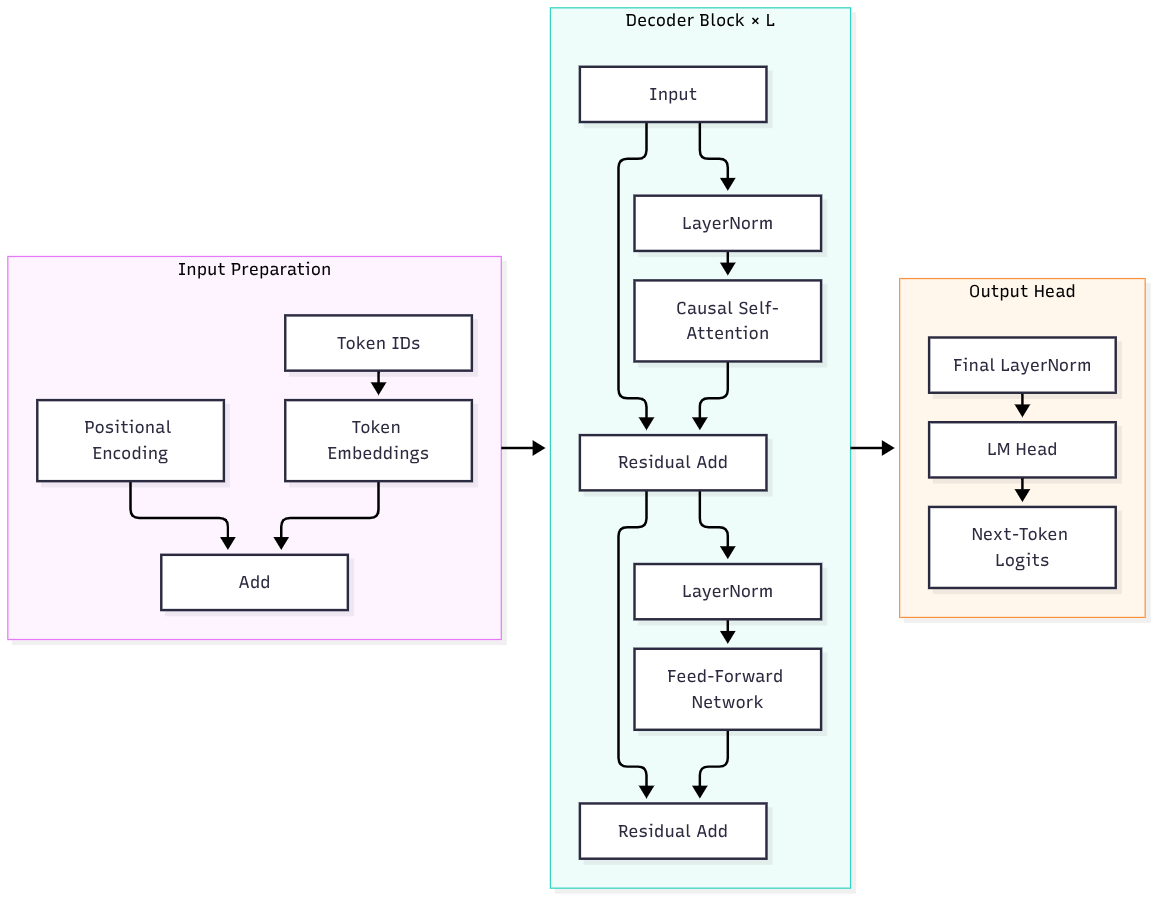


Students must implement the positional encoding, layer normalized residual
blocks, decoder stack, and language-model head while preserving causal
attention and the specified parameter budget.

**Additional Experiment**: You are free to explore _PRE_ and _POST_ layer norm as architectural choices apart from the hyperparameters provided you are within the parameter budget.


In [44]:
%%writefile model_arch.py
"""Decoder-only Transformer LM, built from scratch (no built-in Transformer blocks)."""
import math
from dataclasses import dataclass
import torch
import torch.nn as nn
from attention import CausalSelfAttention


@dataclass
class LMConfig:
    vocab_size: int
    d_model: int = 512
    n_layers: int = 4
    n_heads: int = 4
    n_kv_heads: int = 4
    d_ff: int = 1024
    max_seq_len: int = 256
    dropout: float = 0.1
    pos_emb_type: str = "sinusoidal"
    attention_scale: float = None
    norm_first: bool = False


def sinusoidal_positional_encoding(max_len: int, d_model: int) -> torch.Tensor:
    """Return classic Transformer sinusoidal positions with shape (max_len, d_model)."""
    if max_len <= 0 or d_model <= 0:
        raise ValueError("max_len and d_model must be positive")
    position = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)
    even_indices = torch.arange(0, d_model, 2, dtype=torch.float32)
    frequencies = torch.exp(-math.log(10000.0) * even_indices / d_model)
    angles = position * frequencies.unsqueeze(0)
    encoding = torch.zeros(max_len, d_model, dtype=torch.float32)
    encoding[:, 0::2] = torch.sin(angles)
    if d_model > 1:
        encoding[:, 1::2] = torch.cos(angles[:, :encoding[:, 1::2].shape[1]])
    return encoding


class FeedForward(nn.Module):
    def __init__(self, d_model: int, d_ff: int, dropout: float):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    """Configurable pre-norm or post-norm causal decoder block."""
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.norm_first = bool(cfg.norm_first)
        self.ln1 = nn.LayerNorm(cfg.d_model)
        self.attn = CausalSelfAttention(
            cfg.d_model, cfg.n_heads, cfg.max_seq_len, cfg.dropout,
            attention_scale=cfg.attention_scale,
        )
        self.ln2 = nn.LayerNorm(cfg.d_model)
        self.ffn = FeedForward(cfg.d_model, cfg.d_ff, cfg.dropout)

    def forward(self, x):
        if self.norm_first:
            x = x + self.attn(self.ln1(x))
            return x + self.ffn(self.ln2(x))
        x = self.ln1(x + self.attn(x))
        return self.ln2(x + self.ffn(x))


class DecoderLM(nn.Module):
    """The model class imported by the autograder."""
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        if cfg.pos_emb_type == "sinusoidal":
            self.register_buffer(
                "pos_emb",
                sinusoidal_positional_encoding(cfg.max_seq_len, cfg.d_model),
                persistent=False,
            )
        elif cfg.pos_emb_type != "rope":
            raise ValueError("pos_emb_type must be 'sinusoidal' or 'rope'")
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layers)])
        self.ln_f = nn.LayerNorm(cfg.d_model)
        self.head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight

    def forward(self, idx: torch.Tensor) -> torch.Tensor:
        if idx.ndim != 2:
            raise ValueError("idx must have shape (batch, sequence)")
        _, length = idx.shape
        if length > self.cfg.max_seq_len:
            raise ValueError(
                f"Sequence length {length} exceeds max_seq_len={self.cfg.max_seq_len}"
            )
        x = self.tok_emb(idx)
        if self.cfg.pos_emb_type == "sinusoidal":
            x = x + self.pos_emb[:length].to(dtype=x.dtype).unsqueeze(0)
        for block in self.blocks:
            x = block(x)
        return self.head(self.ln_f(x))


Overwriting model_arch.py


In [45]:
# Import the files just written above. Keep this in a separate cell because everything
# after %%writefile in the previous cell is written to model_arch.py rather than run.
import importlib, sys
for _name in ("model_arch", "attention"):
    sys.modules.pop(_name, None)
attention = importlib.import_module("attention")
model_arch = importlib.import_module("model_arch")
LMConfig, DecoderLM = model_arch.LMConfig, model_arch.DecoderLM


### Question 1 execution, dual-GPU, and recovery helpers

The following student-added runtime keeps the two scaling experiments independent and
resumable. Full training remains an explicit action in Q1.3; importing these helpers does
not start a training run.


In [46]:
%%writefile q1_runtime.py
"""Restart-safe, deterministic two-GPU runtime for Assignment 3 Question 1."""
from __future__ import annotations

import copy
import hashlib
import json
import math
import os
import platform
import shutil
import subprocess
import sys
import threading
import time
import traceback
import uuid
import zipfile
from array import array
from concurrent.futures import ThreadPoolExecutor, as_completed
from dataclasses import asdict, dataclass
from datetime import datetime, timezone
from pathlib import Path

import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, Sampler
from tqdm.auto import tqdm

from common import TokenDataset, assert_within_budget, perplexity_of_texts
from model_arch import DecoderLM, LMConfig


SCHEMA_VERSION = 1
SAMPLER_SCHEME = "epoch_randperm_seed_plus_epoch_v1"
_ARCHIVE_LOCK = threading.Lock()
# All checkpoint/manifest writes and archive snapshots share this lock.
_ARTIFACT_LOCK = threading.RLock()
_PLOT_LOCK = threading.Lock()
_TQDM_LOCK = threading.RLock()
tqdm.set_lock(_TQDM_LOCK)


def _utc_now():
    return datetime.now(timezone.utc).isoformat()


def _canonical_json(value):
    return json.dumps(value, sort_keys=True, separators=(",", ":"), ensure_ascii=False)


def _json_hash(value):
    return hashlib.sha256(_canonical_json(value).encode("utf-8")).hexdigest()


def _sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def _hash_int_sequence(values, chunk_items=100_000):
    digest = hashlib.sha256()
    for start in range(0, len(values), chunk_items):
        digest.update(array("q", (int(x) for x in values[start:start + chunk_items])).tobytes())
    return digest.hexdigest()


def _hash_texts(texts):
    digest = hashlib.sha256()
    for text in texts:
        payload = str(text).encode("utf-8")
        digest.update(len(payload).to_bytes(8, "little"))
        digest.update(payload)
    return digest.hexdigest()


def _state_dict_hash(state):
    digest = hashlib.sha256()
    for name in sorted(state):
        tensor = state[name].detach().cpu().contiguous()
        digest.update(name.encode("utf-8"))
        digest.update(str(tensor.dtype).encode("ascii"))
        digest.update(_canonical_json(list(tensor.shape)).encode("ascii"))
        digest.update(tensor.numpy().tobytes())
    return digest.hexdigest()


def _cpu_tree(value):
    if torch.is_tensor(value):
        return value.detach().cpu().clone()
    if isinstance(value, dict):
        return {key: _cpu_tree(item) for key, item in value.items()}
    if isinstance(value, list):
        return [_cpu_tree(item) for item in value]
    if isinstance(value, tuple):
        return tuple(_cpu_tree(item) for item in value)
    return copy.deepcopy(value)


def _atomic_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + f".{uuid.uuid4().hex}.tmp")
    temporary.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding="utf-8")
    json.loads(temporary.read_text(encoding="utf-8"))
    os.replace(temporary, path)


def _torch_load(path, map_location="cpu"):
    try:
        return torch.load(path, map_location=map_location, weights_only=False)
    except TypeError:
        return torch.load(path, map_location=map_location)


def _atomic_plain_torch(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + f".{uuid.uuid4().hex}.tmp")
    torch.save(value, temporary)
    _torch_load(temporary, "cpu")
    os.replace(temporary, path)


def _move_optimizer_state(optimizer, device):
    for state in optimizer.state.values():
        for key, value in state.items():
            if torch.is_tensor(value):
                state[key] = value.to(device)


class DeterministicStepBatchSampler(Sampler):
    """Map every global optimization step to a deterministic shuffled batch."""

    def __init__(self, dataset_size, batch_size, seed, start_step, total_steps):
        self.dataset_size = int(dataset_size)
        self.batch_size = int(batch_size)
        self.seed = int(seed)
        self.start_step = int(start_step)
        self.total_steps = int(total_steps)
        self.batches_per_epoch = self.dataset_size // self.batch_size
        if self.batches_per_epoch < 1:
            raise ValueError(
                f"Dataset has {self.dataset_size} chunks, fewer than batch_size={self.batch_size}."
            )

    def __len__(self):
        return max(0, self.total_steps - self.start_step)

    def __iter__(self):
        cached_epoch, order = None, None
        for step in range(self.start_step, self.total_steps):
            epoch = step // self.batches_per_epoch
            batch_in_epoch = step % self.batches_per_epoch
            if epoch != cached_epoch:
                generator = torch.Generator(device="cpu")
                generator.manual_seed(self.seed + epoch)
                order = torch.randperm(self.dataset_size, generator=generator)
                cached_epoch = epoch
            start = batch_in_epoch * self.batch_size
            yield order[start:start + self.batch_size].tolist()

    def position_after(self, completed_steps):
        return {
            "scheme": SAMPLER_SCHEME,
            "seed": self.seed,
            "epoch": int(completed_steps) // self.batches_per_epoch,
            "batch_in_epoch": int(completed_steps) % self.batches_per_epoch,
            "batches_per_epoch": self.batches_per_epoch,
        }


@dataclass(frozen=True)
class ExperimentPaths:
    root: Path

    @property
    def config(self): return self.root / "config.json"
    @property
    def latest(self): return self.root / "checkpoint.latest.pt"
    @property
    def previous(self): return self.root / "checkpoint.previous.pt"
    @property
    def latest_checksum(self): return self.root / "checkpoint.latest.sha256"
    @property
    def previous_checksum(self): return self.root / "checkpoint.previous.sha256"
    @property
    def best(self): return self.root / "best.pt"
    @property
    def final(self): return self.root / "final.pt"
    @property
    def history(self): return self.root / "history.json"
    @property
    def metrics(self): return self.root / "metrics.json"
    @property
    def status(self): return self.root / "status.json"


class Q1Runtime:
    def __init__(self, *, tokenizer, train_ids, held_out, base_config, train_steps,
                 batch_size, seed, tokenizer_fingerprint, smoke_test,
                 project_root=".", checkpoint_steps=50, checkpoint_seconds=300,
                 archive_seconds=600, learning_rate=3e-4, use_amp=True):
        self.tokenizer = tokenizer
        self.train_ids = [int(value) for value in train_ids]
        self.held_out = list(held_out)
        self.base_config = dict(base_config)
        self.train_steps = int(train_steps)
        self.batch_size = int(batch_size)
        self.seed = int(seed)
        self.tokenizer_fingerprint = str(tokenizer_fingerprint)
        self.smoke_test = bool(smoke_test)
        self.checkpoint_steps = int(checkpoint_steps)
        self.checkpoint_seconds = float(checkpoint_seconds)
        self.archive_seconds = float(archive_seconds)
        self.learning_rate = float(learning_rate)
        self.use_amp = bool(use_amp)
        self.project_root = Path(project_root).resolve()
        self.mode = "smoke" if self.smoke_test else "full"
        self.root = self.project_root / "artifacts" / self.mode / "q1"
        self.analysis_dir = self.root / "analysis"
        self.plot_dir = self.root / "plots"
        self.source_dir = self.root / "source_snapshots"
        self.manifest_dir = self.root / "manifests"
        for directory in (self.root, self.analysis_dir, self.plot_dir,
                          self.source_dir, self.manifest_dir):
            directory.mkdir(parents=True, exist_ok=True)
        self.train_ids_hash = _hash_int_sequence(self.train_ids)
        self.held_out_hash = _hash_texts(self.held_out)
        self.dataset = TokenDataset(self.train_ids, int(self.base_config["max_seq_len"]))
        if len(self.dataset) < self.batch_size:
            raise ValueError("TokenDataset is too small for the configured training batch size.")
        self.eval_steps = sorted({
            max(1, int(round(self.train_steps * fraction)))
            for fraction in (0.2, 0.4, 0.6, 0.8, 1.0)
        })
        self._last_archive_time = 0.0
        self._stop_event = threading.Event()
        self.snapshot_sources()

    def paths(self, label):
        return ExperimentPaths(self.root / label)

    def _cfg(self, scale):
        values = dict(self.base_config)
        values["attention_scale"] = scale
        return LMConfig(**values)

    def _source_hashes(self):
        hashes = {}
        for name in ("a1_tokenizer.py", "attention.py", "model_arch.py", "q1_runtime.py"):
            path = self.project_root / name
            if path.is_file():
                hashes[name] = _sha256_file(path)
        return hashes

    def snapshot_sources(self):
        for name in ("a1_tokenizer.py", "attention.py", "model_arch.py", "q1_runtime.py"):
            source = self.project_root / name
            destination = self.source_dir / name
            if source.is_file():
                if destination.is_file() and _sha256_file(destination) != _sha256_file(source):
                    versioned = self.source_dir / f"{source.stem}.{_sha256_file(source)[:12]}{source.suffix}"
                    shutil.copy2(source, versioned)
                else:
                    shutil.copy2(source, destination)

    def _canonical_initial_state(self):
        path = self.manifest_dir / "canonical_initial_state.pt"
        signature = {
            "base_config_without_scale": {
                key: value for key, value in self.base_config.items() if key != "attention_scale"
            },
            "seed": self.seed,
            "source_hashes": self._source_hashes(),
        }
        signature_hash = _json_hash(signature)
        if path.is_file():
            payload = _torch_load(path, "cpu")
            if payload.get("signature_hash") != signature_hash:
                raise RuntimeError(
                    "Existing canonical initialization is incompatible with current code/config. "
                    f"Move aside {path}; it was not overwritten."
                )
            return payload["state_dict"], payload["state_dict_hash"]
        cpu_rng_before = torch.get_rng_state()
        try:
            torch.manual_seed(self.seed)
            model = DecoderLM(self._cfg(None)).cpu()
            state = _cpu_tree(model.state_dict())
        finally:
            torch.set_rng_state(cpu_rng_before)
        state_hash = _state_dict_hash(state)
        _atomic_plain_torch(path, {
            "schema_version": SCHEMA_VERSION,
            "signature": signature,
            "signature_hash": signature_hash,
            "state_dict": state,
            "state_dict_hash": state_hash,
            "created_utc": _utc_now(),
        })
        return state, state_hash

    def _spec(self, label, scale, init_hash):
        cfg = asdict(self._cfg(scale))
        strict = {
            "schema_version": SCHEMA_VERSION,
            "experiment_id": f"q1-{self.mode}-{label}",
            "label": label,
            "architecture": cfg,
            "optimizer": {"name": "Adam", "lr": self.learning_rate},
            "target_steps": self.train_steps,
            "batch_size": self.batch_size,
            "seed": self.seed,
            "sampler_scheme": SAMPLER_SCHEME,
            "tokenizer_fingerprint": self.tokenizer_fingerprint,
            "train_ids_hash": self.train_ids_hash,
            "held_out_hash": self.held_out_hash,
            "initial_state_hash": init_hash,
            "smoke_test": self.smoke_test,
            "source_hashes": self._source_hashes(),
        }
        strict["trajectory_hash"] = _json_hash(strict)
        return strict

    def _write_config(self, spec):
        path = self.paths(spec["label"]).config
        if path.is_file():
            existing = json.loads(path.read_text(encoding="utf-8"))
            if existing.get("trajectory_hash") != spec["trajectory_hash"]:
                raise RuntimeError(f"Incompatible experiment config already exists: {path}")
        else:
            _atomic_json(path, spec)

    @staticmethod
    def _validate_checkpoint(payload, expected_hash):
        required = {
            "schema_version", "trajectory_hash", "model_state", "optimizer_state",
            "completed_step", "tokens_processed", "history", "eval_history",
            "cumulative_active_seconds", "sampler_state",
        }
        missing = required - set(payload) if isinstance(payload, dict) else required
        if missing:
            raise ValueError(f"Checkpoint missing fields: {sorted(missing)}")
        if payload["schema_version"] != SCHEMA_VERSION:
            raise ValueError("Unsupported checkpoint schema version")
        if payload["trajectory_hash"] != expected_hash:
            raise ValueError("Checkpoint trajectory/configuration mismatch")
        if int(payload["completed_step"]) < 0:
            raise ValueError("Invalid completed step")
        return payload

    def _validated_checkpoint_file(self, path, checksum_path, expected_hash):
        path, checksum_path = Path(path), Path(checksum_path)
        if not path.is_file():
            return None
        # A checkpoint is committed only if its matching checksum exists.  This
        # deliberately rejects a new file left between two atomic promotions.
        if not checksum_path.is_file():
            return None
        expected = checksum_path.read_text(encoding="ascii").strip()
        if _sha256_file(path) != expected:
            return None
        try:
            return self._validate_checkpoint(_torch_load(path, "cpu"), expected_hash)
        except Exception:
            return None

    def _load_checkpoint(self, spec):
        paths = self.paths(spec["label"])
        latest = self._validated_checkpoint_file(
            paths.latest, paths.latest_checksum, spec["trajectory_hash"]
        )
        if latest is not None:
            return latest, "latest"
        previous = self._validated_checkpoint_file(
            paths.previous, paths.previous_checksum, spec["trajectory_hash"]
        )
        return (previous, "previous") if previous is not None else (None, None)

    def _save_checkpoint(self, spec, payload):
        """Keep the last committed checkpoint available throughout promotion.

        A latest checkpoint is committed only when its separate SHA256 matches;
        previous is copied from a verified latest, never moved away.  A crash
        between candidate and checksum promotion leaves previous recoverable.
        """
        paths = self.paths(spec["label"])
        paths.root.mkdir(parents=True, exist_ok=True)
        with _ARTIFACT_LOCK:
            candidate = paths.root / (
                f"checkpoint.step_{payload['completed_step']:06d}.{uuid.uuid4().hex}.candidate"
            )
            candidate_checksum = paths.root / (candidate.name + ".sha256.tmp")
            previous_tmp = paths.root / ("checkpoint.previous." + uuid.uuid4().hex + ".tmp")
            previous_checksum_tmp = paths.root / ("checkpoint.previous." + uuid.uuid4().hex + ".sha256.tmp")
            try:
                torch.save(_cpu_tree(payload), candidate)
                loaded = self._validate_checkpoint(
                    _torch_load(candidate, "cpu"), spec["trajectory_hash"]
                )
                if int(loaded["completed_step"]) != int(payload["completed_step"]):
                    raise ValueError("Checkpoint step changed during serialization")
                candidate_hash = _sha256_file(candidate)
                candidate_checksum.write_text(candidate_hash, encoding="ascii")

                # Promote the previous known-good pair while the current latest
                # stays in place.  Do not propagate an invalid latest checkpoint.
                old_latest = self._validated_checkpoint_file(
                    paths.latest, paths.latest_checksum, spec["trajectory_hash"]
                )
                if old_latest is not None:
                    shutil.copy2(paths.latest, previous_tmp)
                    previous_hash = _sha256_file(previous_tmp)
                    previous_checksum_tmp.write_text(previous_hash, encoding="ascii")
                    os.replace(previous_tmp, paths.previous)
                    os.replace(previous_checksum_tmp, paths.previous_checksum)

                # Both replacements are atomic individually.  The old previous
                # survives an interruption between these two operations.
                os.replace(candidate, paths.latest)
                os.replace(candidate_checksum, paths.latest_checksum)
            finally:
                for temporary in (candidate, candidate_checksum, previous_tmp, previous_checksum_tmp):
                    temporary.unlink(missing_ok=True)

    def _status(self, spec, status, **extra):
        _atomic_json(self.paths(spec["label"]).status, {
            "experiment_id": spec["experiment_id"],
            "trajectory_hash": spec["trajectory_hash"],
            "status": status,
            "updated_utc": _utc_now(),
            **extra,
        })

    def _is_complete(self, spec):
        paths = self.paths(spec["label"])
        if not (paths.status.is_file() and paths.metrics.is_file() and paths.final.is_file()):
            return False
        status = json.loads(paths.status.read_text(encoding="utf-8"))
        metrics = json.loads(paths.metrics.read_text(encoding="utf-8"))
        return (
            status.get("status") == "complete"
            and status.get("trajectory_hash") == spec["trajectory_hash"]
            and int(metrics.get("completed_steps", -1)) == self.train_steps
            and math.isfinite(float(metrics.get("held_out_ppl", float("inf"))))
            and len(metrics.get("train_loss_curve", [])) > 0
        )

    def _reset_if_requested(self, label, force):
        paths = self.paths(label)
        if not force or not paths.root.exists():
            return
        backup = paths.root.with_name(paths.root.name + ".reset_" + datetime.now().strftime("%Y%m%d_%H%M%S"))
        shutil.move(paths.root, backup)
        print(f"Explicit reset preserved previous {label} artifacts at {backup}")

    def _checkpoint_payload(self, *, spec, model, optimizer, scaler, step, tokens,
                            history, eval_history, cumulative_seconds, sampler,
                            device, best):
        cuda_rng = None
        if device.type == "cuda":
            cuda_rng = torch.cuda.get_rng_state(device=device).cpu()
        sampler_state = sampler.position_after(step)
        return {
            "schema_version": SCHEMA_VERSION,
            "experiment_id": spec["experiment_id"],
            "trajectory_hash": spec["trajectory_hash"],
            "config": spec,
            "model_state": _cpu_tree(model.state_dict()),
            "optimizer_state": _cpu_tree(optimizer.state_dict()),
            "scheduler_state": None,
            "scaler_state": _cpu_tree(scaler.state_dict()) if scaler is not None else None,
            "completed_step": int(step),
            "epoch": sampler_state["epoch"],
            "batch_in_epoch": sampler_state["batch_in_epoch"],
            "tokens_processed": int(tokens),
            "history": list(history),
            "eval_history": list(eval_history),
            "best": dict(best),
            "cumulative_active_seconds": float(cumulative_seconds),
            "sampler_state": sampler_state,
            "assigned_device": str(device),
            "cuda_rng_state_for_assigned_device": cuda_rng,
            "created_utc": _utc_now(),
            "environment": {
                "python": sys.version,
                "torch": torch.__version__,
                "platform": platform.platform(),
                "cuda": torch.version.cuda,
            },
        }

    def _run_worker(self, spec, prepared_model, device_name, position, initial_rng_state):
        label, paths = spec["label"], self.paths(spec["label"])
        device = torch.device(device_name)
        self._write_config(spec)
        if self._is_complete(spec):
            print(f"{label}: compatible completed run found; training skipped.")
            return {"label": label, "status": "complete", "skipped": True}
        checkpoint, checkpoint_source = self._load_checkpoint(spec)
        model = prepared_model.to(device)
        assert_within_budget(model)
        optimizer = torch.optim.Adam(model.parameters(), lr=self.learning_rate)
        amp_enabled = self.use_amp and device.type == "cuda"
        try:
            scaler = torch.amp.GradScaler("cuda", enabled=amp_enabled)
        except (AttributeError, TypeError):
            scaler = torch.cuda.amp.GradScaler(enabled=amp_enabled)

        step, tokens, history, eval_history, cumulative_before = 0, 0, [], [], 0.0
        best = {"held_out_ppl": float("inf"), "step": None}
        run_kind = "new"
        if checkpoint is not None:
            model.load_state_dict(checkpoint["model_state"])
            optimizer.load_state_dict(checkpoint["optimizer_state"])
            _move_optimizer_state(optimizer, device)
            if checkpoint.get("scaler_state"):
                scaler.load_state_dict(checkpoint["scaler_state"])
            step = int(checkpoint["completed_step"])
            tokens = int(checkpoint["tokens_processed"])
            history = [row for row in checkpoint["history"] if int(row["step"]) <= step]
            eval_history = [row for row in checkpoint["eval_history"] if int(row["step"]) <= step]
            cumulative_before = float(checkpoint["cumulative_active_seconds"])
            best = dict(checkpoint.get("best", best))
            if device.type == "cuda" and checkpoint.get("cuda_rng_state_for_assigned_device") is not None:
                torch.cuda.set_rng_state(checkpoint["cuda_rng_state_for_assigned_device"], device=device)
            run_kind = f"resumed-{checkpoint_source}"
        elif device.type == "cuda":
            torch.cuda.set_rng_state(initial_rng_state, device=device)
        else:
            torch.set_rng_state(initial_rng_state)

        sampler = DeterministicStepBatchSampler(
            len(self.dataset), self.batch_size, self.seed, step, self.train_steps
        )
        loader = DataLoader(
            self.dataset, batch_sampler=sampler, num_workers=0,
            pin_memory=(device.type == "cuda"),
        )
        self._status(spec, "in_progress", completed_step=step, assigned_device=str(device), run_kind=run_kind)
        session_started = time.perf_counter()
        last_checkpoint_time = session_started
        last_checkpoint_step = step
        completed_normally = False

        try:
            progress = tqdm(
                total=self.train_steps, initial=step, position=position, leave=True,
                desc=f"{label} [{device}] {run_kind}", dynamic_ncols=True,
            )
            model.train()
            for x, y in loader:
                if self._stop_event.is_set():
                    break
                x = x.to(device, non_blocking=True)
                y = y.to(device, non_blocking=True)
                optimizer.zero_grad(set_to_none=True)
                with torch.autocast(
                    device_type=device.type,
                    dtype=torch.float16 if device.type == "cuda" else torch.float32,
                    enabled=amp_enabled,
                ):
                    logits = model(x)
                    loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1))
                if not torch.isfinite(loss):
                    raise FloatingPointError(f"Non-finite training loss at step {step + 1}")
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
                step += 1
                tokens += int(x.numel())
                session_elapsed = time.perf_counter() - session_started
                cumulative = cumulative_before + session_elapsed
                history.append({
                    "step": step,
                    "epoch": sampler.position_after(step)["epoch"],
                    "loss": float(loss.detach()),
                    "learning_rate": float(optimizer.param_groups[0]["lr"]),
                    "tokens_processed": tokens,
                    "elapsed_seconds": cumulative,
                })
                evaluation_happened = False
                if step in self.eval_steps:
                    model.eval()
                    ppl = float(perplexity_of_texts(
                        model, self.tokenizer, self.held_out, device=device,
                        max_len=int(spec["architecture"]["max_seq_len"]),
                    ))
                    model.train()
                    eval_history.append({
                        "step": step,
                        "tokens_processed": tokens,
                        "held_out_ppl": ppl,
                        "elapsed_seconds": cumulative,
                    })
                    evaluation_happened = True
                    if math.isfinite(ppl) and ppl < float(best.get("held_out_ppl", float("inf"))):
                        best = {"held_out_ppl": ppl, "step": step}
                        _atomic_plain_torch(paths.best, _cpu_tree(model.state_dict()))
                now = time.perf_counter()
                checkpoint_due = (
                    step == self.train_steps
                    or evaluation_happened
                    or step - last_checkpoint_step >= self.checkpoint_steps
                    or now - last_checkpoint_time >= self.checkpoint_seconds
                )
                if checkpoint_due:
                    payload = self._checkpoint_payload(
                        spec=spec, model=model, optimizer=optimizer, scaler=scaler,
                        step=step, tokens=tokens, history=history, eval_history=eval_history,
                        cumulative_seconds=cumulative, sampler=sampler, device=device, best=best,
                    )
                    with _ARTIFACT_LOCK:
                        self._save_checkpoint(spec, payload)
                        _atomic_json(paths.history, {
                            "trajectory_hash": spec["trajectory_hash"],
                            "history": history,
                            "eval_history": eval_history,
                        })
                        self._status(spec, "in_progress", completed_step=step,
                                     assigned_device=str(device), last_checkpoint_step=step)
                    last_checkpoint_time, last_checkpoint_step = now, step
                    self.export_recovery_archive(force=False, reason=f"checkpoint-{label}-{step}")
                elapsed = max(1e-9, session_elapsed)
                progress.update(1)
                progress.set_postfix({
                    "loss": f"{float(loss.detach()):.4f}",
                    "lr": f"{optimizer.param_groups[0]['lr']:.2e}",
                    "tok": tokens,
                    "tok/s": f"{(tokens - (checkpoint['tokens_processed'] if checkpoint else 0))/elapsed:.0f}",
                    "total_s": f"{cumulative:.0f}",
                    "ckpt": last_checkpoint_step,
                }, refresh=(step % 5 == 0 or step == self.train_steps))
                if step >= self.train_steps:
                    completed_normally = True
                    break
            progress.close()
            cumulative = cumulative_before + (time.perf_counter() - session_started)
            if not completed_normally:
                payload = self._checkpoint_payload(
                    spec=spec, model=model, optimizer=optimizer, scaler=scaler,
                    step=step, tokens=tokens, history=history, eval_history=eval_history,
                    cumulative_seconds=cumulative, sampler=sampler, device=device, best=best,
                )
                with _ARTIFACT_LOCK:
                    self._save_checkpoint(spec, payload)
                    _atomic_json(paths.history, {
                        "trajectory_hash": spec["trajectory_hash"],
                        "history": history, "eval_history": eval_history,
                    })
                    self._status(spec, "interrupted", completed_step=step, assigned_device=str(device))
                return {"label": label, "status": "interrupted", "completed_step": step}

            if not eval_history or int(eval_history[-1]["step"]) != self.train_steps:
                model.eval()
                final_ppl = float(perplexity_of_texts(
                    model, self.tokenizer, self.held_out, device=device,
                    max_len=int(spec["architecture"]["max_seq_len"]),
                ))
                eval_history.append({
                    "step": step, "tokens_processed": tokens,
                    "held_out_ppl": final_ppl, "elapsed_seconds": cumulative,
                })
            final_ppl = float(eval_history[-1]["held_out_ppl"])
            if not math.isfinite(final_ppl):
                raise FloatingPointError("Final held-out perplexity is not finite")
            metrics = {
                "label": label,
                "attention_scale": spec["architecture"]["attention_scale"],
                "held_out_ppl": final_ppl,
                "train_loss_curve": [float(row["loss"]) for row in history],
                "history": history,
                "eval_history": eval_history,
                "completed_steps": step,
                "tokens_processed": tokens,
                "parameter_count": sum(parameter.numel() for parameter in model.parameters()),
                "cumulative_active_seconds": cumulative,
                "initial_state_hash": spec["initial_state_hash"],
                "trajectory_hash": spec["trajectory_hash"],
            }
            with _ARTIFACT_LOCK:
                _atomic_plain_torch(paths.final, _cpu_tree(model.state_dict()))
                _atomic_json(paths.metrics, metrics)
                _atomic_json(paths.history, {
                    "trajectory_hash": spec["trajectory_hash"],
                    "history": history,
                    "eval_history": eval_history,
                })
                self._status(spec, "complete", completed_step=step, assigned_device=str(device),
                             final_held_out_ppl=final_ppl)
            print(
                f"{label} completed on {device}: session={time.perf_counter()-session_started:.1f}s, "
                f"cumulative={cumulative:.1f}s, ppl={final_ppl:.3f}"
            )
            return {"label": label, "status": "complete", "metrics": metrics}
        except KeyboardInterrupt:
            self._stop_event.set()
            raise
        except Exception as error:
            # A failed worker never removes its last validated checkpoint or its partner's files.
            self._status(spec, "failed", completed_step=step, assigned_device=str(device),
                         error=repr(error), traceback=traceback.format_exc())
            return {"label": label, "status": "failed", "error": repr(error)}
        finally:
            model.to("cpu")
            if device.type == "cuda":
                with torch.cuda.device(device):
                    torch.cuda.empty_cache()

    def run_scaling_pair(self, *, force_retrain=False, require_two_gpus=True,
                         allow_sequential_fallback=False):
        self._stop_event.clear()
        self._reset_if_requested("standard", force_retrain)
        self._reset_if_requested("unscaled", force_retrain)
        initial_state, init_hash = self._canonical_initial_state()
        specs = {
            "standard": self._spec("standard", None, init_hash),
            "unscaled": self._spec("unscaled", 1.0, init_hash),
        }
        for spec in specs.values():
            self._write_config(spec)
        self.snapshot_sources()
        self.export_recovery_archive(force=True, reason="pre-training")
        completed = {label: self._is_complete(spec) for label, spec in specs.items()}
        pending = [label for label in ("standard", "unscaled") if not completed[label]]
        if not pending:
            print("Both Q1 scaling experiments are already complete; no retraining occurred.")
            return self.collect_results()

        gpu_count = torch.cuda.device_count() if torch.cuda.is_available() else 0
        if require_two_gpus and gpu_count < 2 and not allow_sequential_fallback:
            raise RuntimeError(
                f"Q1 full paired training requires two visible CUDA GPUs; found {gpu_count}. "
                "Use a Kaggle dual-GPU runtime. Sequential fallback is intentionally disabled."
            )
        assignments = {"standard": "cuda:0", "unscaled": "cuda:1"}
        if gpu_count < 2:
            fallback = "cuda:0" if gpu_count == 1 else "cpu"
            print(f"CLEAR FALLBACK NOTICE: running pending Q1 jobs sequentially on {fallback}; "
                  "this is not dual-GPU training.")
            assignments = {label: fallback for label in pending}
        models, rng_states = {}, {}
        for label in pending:
            model = DecoderLM(LMConfig(**specs[label]["architecture"]))
            model.load_state_dict(initial_state)
            models[label] = model
            target_device = assignments[label]
            if target_device.startswith("cuda"):
                generator = torch.Generator(device=target_device)
                generator.manual_seed(self.seed)
                rng_states[label] = generator.get_state().cpu()
            else:
                generator = torch.Generator(device="cpu")
                generator.manual_seed(self.seed)
                rng_states[label] = generator.get_state()

        outcomes = {}
        if gpu_count >= 2 and len(pending) > 1:
            print("DUAL-GPU Q1: standard -> cuda:0; unscaled -> cuda:1")
            with ThreadPoolExecutor(max_workers=2, thread_name_prefix="a3-q1-gpu") as pool:
                futures = {
                    pool.submit(
                        self._run_worker, specs[label], models[label], assignments[label],
                        0 if label == "standard" else 1, rng_states[label]
                    ): label for label in pending
                }
                try:
                    for future in as_completed(futures):
                        label = futures[future]
                        try:
                            outcomes[label] = future.result()
                        except BaseException as error:
                            outcomes[label] = {"label": label, "status": "failed", "error": repr(error)}
                except KeyboardInterrupt:
                    self._stop_event.set()
                    for future in futures:
                        try:
                            future.result()
                        except BaseException:
                            pass
                    raise
        else:
            for label in pending:
                outcomes[label] = self._run_worker(
                    specs[label], models[label], assignments[label],
                    0 if label == "standard" else 1, rng_states[label]
                )
        self.export_recovery_archive(force=True, reason="post-pair")
        failures = {label: result for label, result in outcomes.items()
                    if result.get("status") != "complete"}
        if failures:
            raise RuntimeError(
                "One or more Q1 jobs did not complete; successful partner artifacts were preserved: "
                + _canonical_json(failures)
            )
        return self.collect_results()

    def collect_results(self):
        results = {}
        for label in ("standard", "unscaled"):
            path = self.paths(label).metrics
            if not path.is_file():
                raise FileNotFoundError(f"Q1 experiment is not complete: {label} ({path})")
            results[label] = json.loads(path.read_text(encoding="utf-8"))
        return results

    def load_model(self, label="standard", device="cpu"):
        paths = self.paths(label)
        if not paths.config.is_file() or not paths.final.is_file():
            raise FileNotFoundError(f"Completed {label} model artifacts are unavailable.")
        spec = json.loads(paths.config.read_text(encoding="utf-8"))
        model = DecoderLM(LMConfig(**spec["architecture"]))
        model.load_state_dict(_torch_load(paths.final, "cpu"))
        return model.to(device).eval(), LMConfig(**spec["architecture"])

    def export_recovery_archive(self, *, force=False, reason="manual"):
        now = time.monotonic()
        archive_name = "q1_smoke_all_artifacts.zip" if self.smoke_test else "q1_all_artifacts.zip"
        runtime_root = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else self.project_root
        destination = runtime_root / archive_name
        with _ARCHIVE_LOCK, _ARTIFACT_LOCK:
            if not force and destination.is_file() and now - self._last_archive_time < self.archive_seconds:
                return destination
            self.snapshot_sources()
            roots = [self.root, self.project_root / "artifacts" / "shared" / "tokenizer"]
            submission = self.project_root / "submissions" / "q1"
            if submission.is_dir():
                roots.append(submission)
            files = []
            for root in roots:
                if not root.is_dir():
                    continue
                for path in root.rglob("*"):
                    if path.is_file() and not any(part.endswith((".tmp", ".candidate")) for part in path.parts):
                        files.append(path.resolve())
            analysis_log = self.project_root / "analysis_log.json"
            if analysis_log.is_file():
                files.append(analysis_log.resolve())
            files = sorted(set(files), key=lambda p: str(p))
            manifest = {"schema_version": 1, "created_utc": _utc_now(), "reason": reason,
                        "mode": self.mode, "files": {}}
            temporary = destination.with_name(destination.name + f".{uuid.uuid4().hex}.tmp")
            with zipfile.ZipFile(temporary, "w") as archive:
                for path in files:
                    rel = path.relative_to(self.project_root).as_posix()
                    info = {"sha256": _sha256_file(path), "size": path.stat().st_size}
                    manifest["files"][rel] = info
                    compression = zipfile.ZIP_STORED if path.suffix == ".pt" else zipfile.ZIP_DEFLATED
                    archive.write(path, arcname=rel, compress_type=compression)
                # Notebook outputs may lag the live Kaggle editor; snapshot only
                # when an actual readable file is available.  Always also save a
                # Kaggle notebook version externally after training.
                notebook_candidates = (
                    self.project_root / "copy_assignment3.ipynb",
                    Path("/kaggle/working/copy_assignment3.ipynb"),
                )
                for notebook_path in notebook_candidates:
                    if notebook_path.is_file():
                        try:
                            notebook_payload = notebook_path.read_bytes()
                            parsed = json.loads(notebook_payload)
                            if parsed.get("nbformat") != 4 or not isinstance(parsed.get("cells"), list):
                                raise ValueError("Not an nbformat-4 notebook")
                            archive.writestr("recovery/notebook_snapshot.ipynb", notebook_payload,
                                             compress_type=zipfile.ZIP_DEFLATED)
                            manifest["notebook_snapshot_sha256"] = hashlib.sha256(notebook_payload).hexdigest()
                            break
                        except (OSError, ValueError, json.JSONDecodeError):
                            continue
                archive.writestr(
                    "recovery/integrity_manifest.json",
                    json.dumps(manifest, indent=2),
                    compress_type=zipfile.ZIP_DEFLATED,
                )
                archive.writestr(
                    "recovery/recovery_metadata.json",
                    json.dumps({
                        "notebook": "copy_assignment3.ipynb",
                        "reason": reason,
                        "created_utc": _utc_now(),
                        "instructions": "Attach this ZIP plus the Assignment-3 student package, then run setup top-to-bottom.",
                    }, indent=2),
                    compress_type=zipfile.ZIP_DEFLATED,
                )
            with zipfile.ZipFile(temporary) as archive:
                if archive.testzip() is not None:
                    raise ValueError("New recovery archive failed CRC validation")
                saved_manifest = json.loads(archive.read("recovery/integrity_manifest.json"))
                if "notebook_snapshot_sha256" in saved_manifest:
                    snapshot = archive.read("recovery/notebook_snapshot.ipynb")
                    if hashlib.sha256(snapshot).hexdigest() != saved_manifest["notebook_snapshot_sha256"]:
                        raise ValueError("Notebook snapshot integrity check failed")
                for rel, info in saved_manifest["files"].items():
                    payload = archive.read(rel)
                    if len(payload) != int(info["size"]):
                        raise ValueError(f"Recovery ZIP size validation failed for {rel}")
                    if hashlib.sha256(payload).hexdigest() != info["sha256"]:
                        raise ValueError(f"Recovery ZIP checksum validation failed for {rel}")
            previous = destination.with_name(destination.stem + ".previous.zip")
            if destination.is_file():
                previous_tmp = previous.with_name(previous.name + f".{uuid.uuid4().hex}.tmp")
                try:
                    shutil.copy2(destination, previous_tmp)
                    with zipfile.ZipFile(previous_tmp) as prior:
                        if prior.testzip() is not None:
                            raise ValueError("Existing archive failed CRC; refusing to promote it to previous")
                    os.replace(previous_tmp, previous)
                finally:
                    previous_tmp.unlink(missing_ok=True)
            os.replace(temporary, destination)
            self._last_archive_time = now
            print(f"Validated Q1 recovery archive ({reason}): {destination}")
            return destination

    def completion_report(self):
        report = {"mode": self.mode, "experiments": {}, "submission": {}, "sources": {}}
        for label in ("standard", "unscaled"):
            paths = self.paths(label)
            report["experiments"][label] = {
                "config": paths.config.is_file(), "latest": paths.latest.is_file(),
                "final": paths.final.is_file(), "metrics": paths.metrics.is_file(),
                "status": json.loads(paths.status.read_text()).get("status") if paths.status.is_file() else "missing",
            }
        sub = self.project_root / "submissions" / "q1"
        for name in ("model.pt", "config.json", "metrics.json", "attention.py", "model_arch.py"):
            report["submission"][name] = (sub / name).is_file()
        for name in ("a1_tokenizer.py", "attention.py", "model_arch.py", "q1_runtime.py"):
            report["sources"][name] = (self.source_dir / name).is_file()
        return report

    def run_smoke_tests(self):
        smoke_root = self.project_root / "artifacts" / "_smoke" / "q1_runtime"
        if smoke_root.exists():
            shutil.rmtree(smoke_root)
        smoke_root.mkdir(parents=True)
        checks = {}
        cfg_values = dict(self.base_config)
        cfg_values.update({"d_model": 32, "n_layers": 1, "n_heads": 4,
                           "n_kv_heads": 4, "d_ff": 64, "max_seq_len": 16,
                           "dropout": 0.0, "attention_scale": None})
        cfg = LMConfig(**cfg_values)
        model = DecoderLM(cfg)
        x = torch.randint(0, cfg.vocab_size, (2, 12))
        logits = model(x)
        checks["forward_shape"] = list(logits.shape) == [2, 12, cfg.vocab_size]
        x_changed = x.clone(); x_changed[:, 7:] = torch.randint(0, cfg.vocab_size, x_changed[:, 7:].shape)
        with torch.no_grad():
            a, b = model.eval()(x), model.eval()(x_changed)
        checks["causal_prefix"] = bool(torch.allclose(a[:, :7], b[:, :7], atol=1e-5, rtol=1e-5))
        model.train(); loss = F.cross_entropy(model(x).reshape(-1, cfg.vocab_size), x.reshape(-1))
        loss.backward()
        checks["finite_gradients"] = all(
            parameter.grad is None or bool(torch.isfinite(parameter.grad).all())
            for parameter in model.parameters()
        )
        checks["weight_tying"] = model.head.weight is model.tok_emb.weight
        checks["parameter_budget"] = sum(p.numel() for p in model.parameters()) <= 50_000_000
        sampler_a = list(DeterministicStepBatchSampler(100, 4, self.seed, 0, 8))
        sampler_b = list(DeterministicStepBatchSampler(100, 4, self.seed, 3, 8))
        checks["exact_sampler_resume"] = sampler_a[3:] == sampler_b
        optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
        checkpoint_path = smoke_root / "optimizer_roundtrip.pt"
        _atomic_plain_torch(checkpoint_path, {
            "model": _cpu_tree(model.state_dict()), "optimizer": _cpu_tree(optimizer.state_dict())
        })
        restored = _torch_load(checkpoint_path, "cpu")
        model_2 = DecoderLM(cfg); model_2.load_state_dict(restored["model"])
        optimizer_2 = torch.optim.Adam(model_2.parameters(), lr=1e-3)
        optimizer_2.load_state_dict(restored["optimizer"])
        checks["checkpoint_optimizer_roundtrip"] = _state_dict_hash(model.state_dict()) == _state_dict_hash(model_2.state_dict())
        failures = []
        with ThreadPoolExecutor(max_workers=2) as pool:
            good = pool.submit(lambda: "preserved")
            bad = pool.submit(lambda: (_ for _ in ()).throw(RuntimeError("injected")))
            checks["partner_success_survives"] = good.result() == "preserved"
            try: bad.result()
            except RuntimeError: failures.append("injected")
        checks["injected_failure_observed"] = failures == ["injected"]
        if torch.cuda.device_count() >= 2:
            def gpu_probe(device_name):
                local = DecoderLM(cfg).to(device_name).eval()
                value = local(torch.randint(0, cfg.vocab_size, (1, 8), device=device_name))
                return str(value.device)
            with ThreadPoolExecutor(max_workers=2) as pool:
                devices = {pool.submit(gpu_probe, "cuda:0"), pool.submit(gpu_probe, "cuda:1")}
                seen = {future.result() for future in devices}
            checks["dual_gpu_independence"] = seen == {"cuda:0", "cuda:1"}
        else:
            checks["dual_gpu_independence"] = None
        zip_path = smoke_root / "integrity.zip"
        payload_path = smoke_root / "payload.json"
        _atomic_json(payload_path, {"ok": True})
        with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
            archive.write(payload_path, arcname="payload.json")
        with zipfile.ZipFile(zip_path) as archive:
            checks["zip_crc"] = archive.testzip() is None
        report = {"created_utc": _utc_now(), "checks": checks,
                  "all_available_passed": all(value for value in checks.values() if value is not None)}
        _atomic_json(smoke_root / "smoke_report.json", report)
        print(json.dumps(report, indent=2))
        return report


Overwriting q1_runtime.py


In [47]:
# Configure the reusable Q1 runtime. This cell only prepares state; it does not train.
import importlib
sys.modules.pop("q1_runtime", None)
q1_runtime_module = importlib.import_module("q1_runtime")

q1_base_config = {
    "vocab_size": VOCAB_SIZE,
    "d_model": MODEL_DIM,
    "n_layers": MODEL_LAYERS,
    "n_heads": 4,
    "n_kv_heads": 4,
    "d_ff": MODEL_FF,
    "max_seq_len": MODEL_SEQ_LEN,
    "dropout": 0.1,
    "pos_emb_type": "sinusoidal",
    "attention_scale": None,
    "norm_first": False,
}
q1_runtime = q1_runtime_module.Q1Runtime(
    tokenizer=tokenizer,
    train_ids=train_ids,
    held_out=held_out,
    base_config=q1_base_config,
    train_steps=TRAIN_STEPS,
    batch_size=TRAIN_BATCH_SIZE,
    seed=SEED,
    tokenizer_fingerprint=TOKENIZER_FINGERPRINT,
    smoke_test=SMOKE_TEST,
    checkpoint_steps=50,
    checkpoint_seconds=5 * 60,
    archive_seconds=10 * 60,
    learning_rate=3e-4,
    use_amp=True,
)
print("Q1 artifact root:", q1_runtime.root)
print("Q1 evaluation steps:", q1_runtime.eval_steps)


Q1 artifact root: /kaggle/working/assignment_3/artifacts/full/q1
Q1 evaluation steps: [100, 200, 300, 400, 500]


In [ ]:
# Lightweight infrastructure tests are isolated from real experiment artifacts.
RUN_Q1_INFRA_SMOKE_TESTS = SMOKE_TEST  # set True manually in a full-mode validation session
if RUN_Q1_INFRA_SMOKE_TESTS:
    q1_smoke_report = q1_runtime.run_smoke_tests()
    if not q1_smoke_report["all_available_passed"]:
        raise AssertionError("One or more available Q1 smoke checks failed.")
else:
    print("Q1 infrastructure smoke tests skipped; set RUN_Q1_INFRA_SMOKE_TESTS=True to run them.")


## 1.3 Baseline training, parameter-budget check, and held-out perplexity [30 Marks]

Train the baseline model for next-token prediction using Adam and cross-entropy loss.
Construct the training batches from the tokenized corpus, log the training loss during
optimization, verify the total parameter count, and evaluate the final model on the
held-out set.

Use the provided `perplexity_of_texts(...)` helper for the reported held-out perplexity
so every submission follows the same course evaluation convention. Do not replace it
with a separately defined perplexity formula.

Use the same baseline configuration as the reference point for the later ablations.
`TRAIN_STEPS` is a convenience default, not a hard or exact training limit; report the
actual number of optimization steps used.


In [48]:
# Q1.3 + Q1.4 principal training action.
# Standard scaling is the Q1 baseline; it is trained once, concurrently with unscaled.
Q1_FORCE_RETRAIN = False       # explicit reset only; old work is preserved in a timestamped folder
Q1_ALLOW_SEQUENTIAL_FALLBACK = SMOKE_TEST

q1_pair_results = q1_runtime.run_scaling_pair(
    force_retrain=Q1_FORCE_RETRAIN,
    require_two_gpus=not SMOKE_TEST,
    allow_sequential_fallback=Q1_ALLOW_SEQUENTIAL_FALLBACK,
)

q1_analysis_device = torch.device(
    "cuda:0" if torch.cuda.is_available() else
    ("mps" if torch.backends.mps.is_available() else "cpu")
)
model, cfg = q1_runtime.load_model("standard", device=q1_analysis_device)
q1_standard_result = q1_pair_results["standard"]
n_params = assert_within_budget(model)
train_loss_curve = q1_standard_result["train_loss_curve"]
held_out_perplexity_q1 = float(q1_standard_result["held_out_ppl"])

print(f"Q1 baseline: {n_params:,} parameters")
print(f"Actual optimization steps: {q1_standard_result['completed_steps']}")
print(f"Held-out sentence-level perplexity: {held_out_perplexity_q1:.4f}")
print("Baseline is the standard-scaling member of the paired experiment; it was not retrained twice.")


Validated Q1 recovery archive (pre-training): /kaggle/working/q1_all_artifacts.zip
DUAL-GPU Q1: standard -> cuda:0; unscaled -> cuda:1


standard [cuda:0] new:   0%|          | 0/500 [00:00<?, ?it/s]

unscaled [cuda:1] new:   0%|          | 0/500 [00:00<?, ?it/s]

unscaled completed on cuda:1: session=37.2s, cumulative=37.1s, ppl=2702.129
standard completed on cuda:0: session=40.2s, cumulative=40.1s, ppl=2624.355
Validated Q1 recovery archive (post-pair): /kaggle/working/q1_all_artifacts.zip
Q1 baseline: 5,203,456 parameters
Actual optimization steps: 500
Held-out sentence-level perplexity: 2624.3546
Baseline is the standard-scaling member of the paired experiment; it was not retrained twice.


## 1.4 Attention-score scaling ablation [30 Marks]

Study the effect of the attention-score scaling factor while keeping the rest of the model and training setup fixed. Write the scores as

$$S = \alpha QK^\top$$

Run the standard setting $\alpha=1/\sqrt{d_k}$, an unscaled setting $\alpha=1$. Compare the resulting training behaviour and held-out perplexity using a comparable experimental budget.

The purpose of the $\frac{1}{\sqrt{d_k}}$ factor is to prevent the magnitude of dot products from growing with the head dimension and pushing the softmax into an excessively saturated regime. Use your experiment to examine what happens when this normalization is changed.


  standard | alpha=0.125000 | held-out ppl=2624.3546 | logged losses=500
  unscaled | alpha=1.000000 | held-out ppl=2702.1288 | logged losses=500


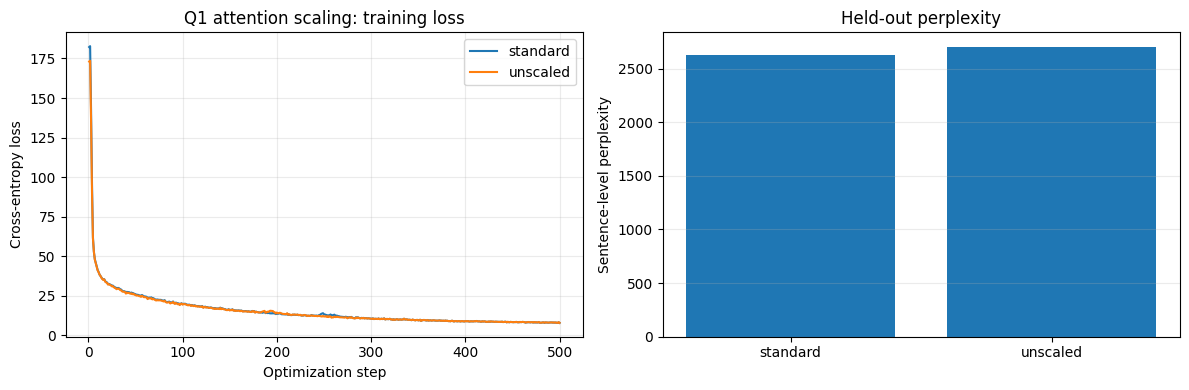

Measured conclusion: standard scaling produced the lower held-out perplexity in this controlled run (2624.3546).


In [49]:
# Read and compare the two persisted runs. This cell never launches training.
q1_pair_results = q1_runtime.collect_results()
attention_scaling_results = [
    {
        "label": label,
        "attention_scale": q1_pair_results[label]["attention_scale"],
        "held_out_ppl": float(q1_pair_results[label]["held_out_ppl"]),
        "train_loss_curve": [float(value) for value in q1_pair_results[label]["train_loss_curve"]],
    }
    for label in ("standard", "unscaled")
]

for row in attention_scaling_results:
    effective_scale = row["attention_scale"]
    if effective_scale is None:
        effective_scale = 1.0 / math.sqrt(cfg.d_model // cfg.n_heads)
    print(
        f"{row['label']:>10s} | alpha={effective_scale:.6f} | "
        f"held-out ppl={row['held_out_ppl']:.4f} | logged losses={len(row['train_loss_curve'])}"
    )

with q1_runtime_module._PLOT_LOCK:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for row in attention_scaling_results:
        axes[0].plot(range(1, len(row["train_loss_curve"]) + 1), row["train_loss_curve"],
                     label=row["label"])
    axes[0].set(title="Q1 attention scaling: training loss", xlabel="Optimization step",
                ylabel="Cross-entropy loss")
    axes[0].grid(alpha=0.25); axes[0].legend()
    axes[1].bar([row["label"] for row in attention_scaling_results],
                [row["held_out_ppl"] for row in attention_scaling_results])
    axes[1].set(title="Held-out perplexity", ylabel="Sentence-level perplexity")
    axes[1].grid(axis="y", alpha=0.25)
    fig.tight_layout()
    _scaling_plot = q1_runtime.plot_dir / "attention_scaling_comparison.png"
    fig.savefig(_scaling_plot, dpi=170, bbox_inches="tight")
    plt.show()

_better_scaling = min(attention_scaling_results, key=lambda row: row["held_out_ppl"])
print(
    f"Measured conclusion: {_better_scaling['label']} scaling produced the lower held-out "
    f"perplexity in this controlled run ({_better_scaling['held_out_ppl']:.4f})."
)


## 1.5 Extrinsic evaluation [30 Marks]

Design a small **zero-shot probe set of approximately 5–10 examples** to evaluate what the baseline language model has learned from the corpus beyond held-out perplexity. Include **more than one** of the probe formats below. Your examples should be related to patterns, facts, entities, or continuations that are meaningful for this corpus rather than testing unrelated general knowledge.

### A. Closed QA / cloze-style short-answer probes

A closed QA probe has a **specific expected answer**. For a decoder-only language model, it is often easiest to phrase this as a short prompt whose continuation should contain that answer. For example:

- Prompt: `Harry's owl is named`  
  Expected answer: `Hedwig`

For these probes, report a numerical quantity that reflects how strongly the model supports the expected answer. Depending on your implementation, this could be the answer's log-probability, its next-token probability when appropriate and whether it appears in the model's top-$k$ predictions. If an answer contains multiple BPE tokens, score the complete answer rather than assuming that one token corresponds to one word.

### B. Forced-choice probes

A forced-choice probe gives the model the **same prefix** followed by two or more candidate continuations. The model should prefer the candidate to which it assigns the larger continuation probability (or log-probability). For example:

- Prefix: `Harry raised his wand and shouted, Expecto`  
  Candidate A: ` Patronum`  
  Candidate B: ` Toaster`

Score **all tokens in each candidate continuation**, not only the first token. Report the candidate scores and indicate which option the model preferred.

### C. Free-form continuation probes

A continuation probe asks the model to generate several new tokens from a short prompt. This is useful for examining coherence, local style, character/entity consistency, and whether the model produces plausible corpus-specific text. For example:

- Prompt: `Harry stepped into the Great Hall and`

Generate a short continuation (for example, around 20–50 new tokens) and show a few representative outputs. There is usually no single correct continuation, so this part should be analysed qualitatively rather than reduced to exact-match accuracy. Comment briefly on what the model does well and where it fails—for example, repetition, incoherent syntax, incorrect entities, or a continuation that is fluent but inconsistent with the corpus.


In [50]:
# Q1.5: corpus-specific closed, forced-choice, and free-generation probes.
def q1_continuation_logprob(prefix, continuation):
    prefix_ids = [int(value) for value in tokenizer.encode(prefix)]
    continuation_ids = [int(value) for value in tokenizer.encode(continuation)]
    if not prefix_ids or not continuation_ids:
        return float("-inf")
    full_ids = prefix_ids + continuation_ids
    full_ids = full_ids[-(cfg.max_seq_len + 1):]
    continuation_start = max(1, len(full_ids) - len(continuation_ids))
    x = torch.tensor(full_ids[:-1], dtype=torch.long, device=q1_analysis_device).unsqueeze(0)
    with torch.no_grad():
        log_probs = F.log_softmax(model.eval()(x), dim=-1)
    score = 0.0
    for token_position in range(continuation_start, len(full_ids)):
        score += float(log_probs[0, token_position - 1, full_ids[token_position]])
    return score


def q1_generate(prompt, max_new_tokens=30, temperature=0.8, top_k=20, seed=SEED):
    ids = [int(value) for value in tokenizer.encode(prompt)]
    generator_device = q1_analysis_device.type if q1_analysis_device.type != "cuda" else q1_analysis_device
    generator = torch.Generator(device=generator_device)
    generator.manual_seed(int(seed))
    model.eval()
    for _ in range(max_new_tokens):
        context = ids[-cfg.max_seq_len:]
        x = torch.tensor(context, dtype=torch.long, device=q1_analysis_device).unsqueeze(0)
        with torch.no_grad():
            logits = model(x)[0, -1] / max(float(temperature), 1e-6)
        k = min(int(top_k), logits.numel())
        values, indices = torch.topk(logits, k)
        probabilities = torch.softmax(values, dim=-1)
        sampled = torch.multinomial(probabilities, 1, generator=generator)
        ids.append(int(indices[sampled].item()))
    return tokenizer.decode(ids)


q1_scored_probes = [
    {"format": "closed_cloze", "prefix": "Harry's owl is named",
     "candidates": [" Hedwig", " Crookshanks", " Scabbers"], "expected": " Hedwig"},
    {"format": "closed_cloze", "prefix": "The headmaster of Hogwarts is",
     "candidates": [" Albus Dumbledore", " Lord Voldemort", " Hagrid"],
     "expected": " Albus Dumbledore"},
    {"format": "closed_cloze", "prefix": "Harry belongs to the house of",
     "candidates": [" Gryffindor", " Slytherin", " Ravenclaw"], "expected": " Gryffindor"},
    {"format": "forced_choice", "prefix": "Harry raised his wand and shouted, Expecto",
     "candidates": [" Patronum", " Toaster"], "expected": " Patronum"},
    {"format": "forced_choice", "prefix": "Platform nine and three-quarters leads to",
     "candidates": [" Hogwarts", " the moon"], "expected": " Hogwarts"},
    {"format": "forced_choice", "prefix": "Ron and Hermione were Harry's",
     "candidates": [" friends", " professors"], "expected": " friends"},
]

q1_probe_records = []
for probe in q1_scored_probes:
    scores = {candidate: q1_continuation_logprob(probe["prefix"], candidate)
              for candidate in probe["candidates"]}
    prediction = max(scores, key=scores.get)
    record = {**probe, "candidate_log_probabilities": scores, "prediction": prediction,
              "correct": prediction == probe["expected"],
              "scoring_rule": "largest sum of log-probabilities over every candidate BPE token"}
    q1_probe_records.append(record)
    print(json.dumps(record, indent=2))

q1_generation_records = []
for probe_index, prompt in enumerate((
    "Harry stepped into the Great Hall and",
    "Hermione opened the old book and whispered",
)):
    continuation = q1_generate(prompt, seed=SEED + probe_index)
    q1_generation_records.append({
        "format": "free_form", "prompt": prompt, "generated_text": continuation,
        "evaluation": "Qualitatively inspect syntax, repetition, entity consistency, and local corpus style.",
    })
    print("\nPROMPT:", prompt, "\nGENERATION:", continuation)

extrinsic_probe_accuracy = (
    sum(int(record["correct"]) for record in q1_probe_records) / len(q1_probe_records)
)
q1_extrinsic_results = {
    "accuracy": extrinsic_probe_accuracy,
    "correct": sum(int(record["correct"]) for record in q1_probe_records),
    "total_scored": len(q1_probe_records),
    "scored_probes": q1_probe_records,
    "qualitative_generations": q1_generation_records,
}
q1_runtime_module._atomic_json(q1_runtime.analysis_dir / "extrinsic_probes.json", q1_extrinsic_results)
print(f"\nExtrinsic scored-probe accuracy: {extrinsic_probe_accuracy:.3f} "
      f"({q1_extrinsic_results['correct']}/{q1_extrinsic_results['total_scored']})")


{
  "format": "closed_cloze",
  "prefix": "Harry's owl is named",
  "candidates": [
    " Hedwig",
    " Crookshanks",
    " Scabbers"
  ],
  "expected": " Hedwig",
  "candidate_log_probabilities": {
    " Hedwig": -18.180709838867188,
    " Crookshanks": -11.94076919555664,
    " Scabbers": -24.713359832763672
  },
  "prediction": " Crookshanks",
  "correct": false,
  "scoring_rule": "largest sum of log-probabilities over every candidate BPE token"
}
{
  "format": "closed_cloze",
  "prefix": "The headmaster of Hogwarts is",
  "candidates": [
    " Albus Dumbledore",
    " Lord Voldemort",
    " Hagrid"
  ],
  "expected": " Albus Dumbledore",
  "candidate_log_probabilities": {
    " Albus Dumbledore": -16.260523796081543,
    " Lord Voldemort": -23.177783966064453,
    " Hagrid": -7.24647855758667
  },
  "prediction": " Hagrid",
  "correct": false,
  "scoring_rule": "largest sum of log-probabilities over every candidate BPE token"
}
{
  "format": "closed_cloze",
  "prefix": "Harry belo

## 1.6 Perplexity versus training tokens [20 Marks]

Plot held-out perplexity at several checkpoints over the course of training. Use the curve to discuss whether performance is still improving substantially near the end of the run or whether it has begun to plateau at this model size and training budget.

Base the discussion on the measured curve and reported values.


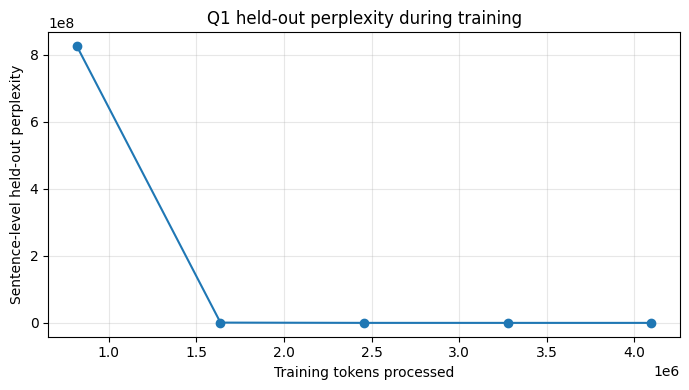

step= 100 | tokens=    819200 | ppl=825762185.3352
step= 200 | tokens=   1638400 | ppl=831517.4657
step= 300 | tokens=   2457600 | ppl=39892.8593
step= 400 | tokens=   3276800 | ppl=7049.8285
step= 500 | tokens=   4096000 | ppl=2624.3546
Measured end-of-run change: +62.77%; performance appears still improving materially.


In [51]:
# Q1.6: the training worker persisted held-out evaluations at predetermined milestones.
q1_standard_result = q1_runtime.collect_results()["standard"]
q1_ppl_curve = q1_standard_result["eval_history"]
if len(q1_ppl_curve) < 2 and not SMOKE_TEST:
    raise RuntimeError("Full training did not preserve enough intermediate PPL measurements.")

with q1_runtime_module._PLOT_LOCK:
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot([row["tokens_processed"] for row in q1_ppl_curve],
            [row["held_out_ppl"] for row in q1_ppl_curve], marker="o")
    ax.set(title="Q1 held-out perplexity during training", xlabel="Training tokens processed",
           ylabel="Sentence-level held-out perplexity")
    ax.grid(alpha=0.3)
    fig.tight_layout()
    q1_ppl_plot = q1_runtime.plot_dir / "perplexity_vs_training_tokens.png"
    fig.savefig(q1_ppl_plot, dpi=170, bbox_inches="tight")
    plt.show()

for row in q1_ppl_curve:
    print(f"step={row['step']:4d} | tokens={row['tokens_processed']:10d} | ppl={row['held_out_ppl']:.4f}")
if len(q1_ppl_curve) >= 2:
    previous, final = q1_ppl_curve[-2]["held_out_ppl"], q1_ppl_curve[-1]["held_out_ppl"]
    relative_change = (previous - final) / max(previous, 1e-12)
    interpretation = "still improving materially" if relative_change > 0.02 else "beginning to plateau"
    print(f"Measured end-of-run change: {relative_change:+.2%}; performance appears {interpretation}.")


## 1.7 Highest-loss tokens [15 Marks]

Compute token-level negative log-likelihood on several held-out sentences and identify the target tokens with the largest losses. Group or describe the difficult tokens you observe, such as proper nouns, rare subwords, punctuation, or common function words.

Use these observations to comment on what the tokenizer–model combination finds difficult on this corpus.


In [52]:
# Q1.7: token-level NLL on several held-out sentences.
q1_token_losses = []
model.eval()
for sentence_index, sentence in enumerate(held_out[:8]):
    sentence_ids = [int(value) for value in tokenizer.encode(sentence)][:cfg.max_seq_len + 1]
    if len(sentence_ids) < 2:
        continue
    x = torch.tensor(sentence_ids[:-1], dtype=torch.long, device=q1_analysis_device).unsqueeze(0)
    y = torch.tensor(sentence_ids[1:], dtype=torch.long, device=q1_analysis_device)
    with torch.no_grad():
        logits = model(x)[0]
        losses = F.cross_entropy(logits, y, reduction="none")
    for position, (token_id, token_loss) in enumerate(zip(sentence_ids[1:], losses.tolist()), start=1):
        rendered = tokenizer.decode([int(token_id)])
        q1_token_losses.append({
            "sentence_index": sentence_index, "target_position": position,
            "token_id": int(token_id), "token": rendered,
            "negative_log_likelihood": float(token_loss),
        })

q1_highest_loss_tokens = sorted(
    q1_token_losses, key=lambda row: row["negative_log_likelihood"], reverse=True
)[:25]
for row in q1_highest_loss_tokens:
    print(f"NLL={row['negative_log_likelihood']:.4f} | sentence={row['sentence_index']} "
          f"| position={row['target_position']} | token={row['token']!r}")
q1_difficult_token_summary = {
    "punctuation_like": sum(not any(ch.isalnum() for ch in row["token"])
                            for row in q1_highest_loss_tokens),
    "contains_uppercase": sum(any(ch.isupper() for ch in row["token"])
                              for row in q1_highest_loss_tokens),
    "short_subword": sum(len(row["token"].strip()) <= 2 for row in q1_highest_loss_tokens),
}
print("Observed high-loss-token categories:", q1_difficult_token_summary)
q1_runtime_module._atomic_json(q1_runtime.analysis_dir / "highest_loss_tokens.json", {
    "evaluated_sentence_count": min(8, len(held_out)),
    "top_tokens": q1_highest_loss_tokens,
    "category_counts": q1_difficult_token_summary,
})


NLL=31.7767 | sentence=4 | position=21 | token='Polyjuice'
NLL=27.4706 | sentence=4 | position=7 | token='stal'
NLL=23.4359 | sentence=5 | position=15 | token='tonight'
NLL=22.0754 | sentence=1 | position=2 | token='xes'
NLL=20.9470 | sentence=6 | position=7 | token='sto'
NLL=20.6885 | sentence=7 | position=1 | token='everything'
NLL=20.3004 | sentence=1 | position=17 | token='born'
NLL=19.4676 | sentence=5 | position=22 | token='Hedwig'
NLL=18.7584 | sentence=3 | position=2 | token='P'
NLL=18.4035 | sentence=5 | position=32 | token='package'
NLL=17.1543 | sentence=0 | position=13 | token='ones'
NLL=17.0350 | sentence=4 | position=25 | token='slipped'
NLL=16.7725 | sentence=5 | position=11 | token='say'
NLL=16.5017 | sentence=7 | position=3 | token='dark'
NLL=16.1087 | sentence=4 | position=11 | token='Car'
NLL=15.7131 | sentence=6 | position=4 | token='Rosmerta'
NLL=15.1191 | sentence=2 | position=15 | token='Moaning'
NLL=14.5877 | sentence=6 | position=21 | token='appear'
NLL=14.4328

## 1.8 Embedding geometry [20 Marks]

Inspect the learned token embeddings for a small set of character names and common nouns. When a word is represented by multiple BPE tokens, use a clearly stated aggregation rule. Compute cosine similarities,
$$\cos(u,v)=\frac{u^\top v}{\|u\|_2\|v\|_2},$$

and report the nearest or most similar items for the selected examples.

Discuss whether the geometry shows interpretable structure or is better explained by local co-occurrence and frequency effects at this scale.


In [53]:
# Q1.8: represent a word by the mean of all of its BPE token embeddings.
q1_embedding_words = [
    "Harry", "Hermione", "Ron", "Dumbledore", "Voldemort",
    "wand", "school", "magic", "friend", "teacher", "book", "house",
]
embedding_table = model.tok_emb.weight.detach()
q1_word_vectors, q1_word_token_ids = {}, {}
for word in q1_embedding_words:
    token_ids = [int(value) for value in tokenizer.encode(word)]
    if not token_ids:
        continue
    ids_tensor = torch.tensor(token_ids, dtype=torch.long, device=embedding_table.device)
    vector = embedding_table.index_select(0, ids_tensor).mean(dim=0)
    q1_word_vectors[word] = F.normalize(vector, dim=0)
    q1_word_token_ids[word] = token_ids

q1_embedding_geometry = {}
for word, vector in q1_word_vectors.items():
    neighbours = sorted(
        ((other, float(torch.dot(vector, other_vector)))
         for other, other_vector in q1_word_vectors.items() if other != word),
        key=lambda item: item[1], reverse=True,
    )[:5]
    q1_embedding_geometry[word] = {
        "bpe_token_ids": q1_word_token_ids[word],
        "nearest_selected_words": [{"word": other, "cosine_similarity": similarity}
                                   for other, similarity in neighbours],
    }
    print(word, "->", ", ".join(f"{other} ({similarity:.3f})" for other, similarity in neighbours))

q1_runtime_module._atomic_json(q1_runtime.analysis_dir / "embedding_geometry.json", {
    "aggregation_rule": "arithmetic mean of the learned embeddings of every BPE token in the word",
    "results": q1_embedding_geometry,
    "interpretation_caution": (
        "At this scale, similarity may reflect local co-occurrence and token frequency rather than stable semantics."
    ),
})
print("Interpretation: inspect whether character names cluster; weak/mixed clustering is evidence "
      "that local co-occurrence and frequency dominate at this training scale.")


Harry -> magic (0.192), Ron (0.078), Dumbledore (0.071), wand (0.049), friend (0.042)
Hermione -> wand (0.101), book (0.075), house (0.043), teacher (0.017), Ron (0.013)
Ron -> Harry (0.078), Voldemort (0.073), wand (0.053), friend (0.034), Hermione (0.013)
Dumbledore -> Harry (0.071), book (0.068), teacher (0.066), magic (0.030), friend (0.027)
Voldemort -> Ron (0.073), book (0.070), friend (0.038), Harry (0.019), wand (0.011)
wand -> Hermione (0.101), friend (0.082), Ron (0.053), Harry (0.049), book (0.043)
school -> house (0.122), friend (0.051), magic (0.022), Harry (0.020), wand (-0.010)
magic -> Harry (0.192), teacher (0.054), Dumbledore (0.030), house (0.025), school (0.022)
friend -> book (0.166), wand (0.082), school (0.051), Harry (0.042), Voldemort (0.038)
teacher -> Dumbledore (0.066), magic (0.054), Hermione (0.017), wand (0.015), Voldemort (-0.001)
book -> friend (0.166), Hermione (0.075), Voldemort (0.070), Dumbledore (0.068), wand (0.043)
house -> school (0.122), Hermio

## 1.9 Dialogue versus narration [20 Marks]

Partition the held-out sentences into dialogue-heavy and narration-heavy subsets using a simple, stated rule such as the presence of quotation marks. Compute average sentence-level perplexity for both groups and compare them.

Report the number of examples in each group, the two perplexities and one plausible explanation for the observed direction.


In [54]:
# Q1.9: a sentence is dialogue-heavy when it contains a straight or curly quotation mark.
q1_dialogue_rule = 'contains at least one of: \", “, ”'
dialogue_sentences = [sentence for sentence in held_out if any(mark in sentence for mark in ('"', '“', '”'))]
narration_sentences = [sentence for sentence in held_out if sentence not in dialogue_sentences]
if not dialogue_sentences or not narration_sentences:
    raise RuntimeError("The stated dialogue rule produced an empty subset; report and revise the rule explicitly.")

dialogue_sentence_ppls = [
    float(perplexity_of_texts(model, tokenizer, [sentence], q1_analysis_device,
                              max_len=cfg.max_seq_len))
    for sentence in dialogue_sentences
]
narration_sentence_ppls = [
    float(perplexity_of_texts(model, tokenizer, [sentence], q1_analysis_device,
                              max_len=cfg.max_seq_len))
    for sentence in narration_sentences
]
dialogue_ppl = sum(dialogue_sentence_ppls) / len(dialogue_sentence_ppls)
narration_ppl = sum(narration_sentence_ppls) / len(narration_sentence_ppls)
q1_dialogue_results = {
    "rule": q1_dialogue_rule,
    "dialogue_count": len(dialogue_sentences),
    "narration_count": len(narration_sentences),
    "dialogue_ppl": dialogue_ppl,
    "narration_ppl": narration_ppl,
    "dialogue_sentence_ppls": dialogue_sentence_ppls,
    "narration_sentence_ppls": narration_sentence_ppls,
}
q1_runtime_module._atomic_json(q1_runtime.analysis_dir / "dialogue_vs_narration.json", q1_dialogue_results)
print(json.dumps(q1_dialogue_results, indent=2))
easier = "dialogue" if dialogue_ppl < narration_ppl else "narration"
print(
    f"Measured result: {easier} has lower average sentence-level perplexity. "
    "A plausible corpus-grounded explanation is that repeated dialogue templates and speaker turns "
    "can be easier, while narration may contain rarer descriptions—or the reverse when quotation "
    "punctuation and short turns fragment the tokenizer context."
)


{
  "rule": "contains at least one of: \", \u201c, \u201d",
  "dialogue_count": 15,
  "narration_count": 15,
  "dialogue_ppl": 2385.814076790483,
  "narration_ppl": 2862.8952116645164,
  "dialogue_sentence_ppls": [
    305.5383987924119,
    4069.1160512386796,
    1373.5133430932938,
    2672.249808725356,
    183.83372789416146,
    7912.296923755525,
    2146.05331134747,
    1627.358458755979,
    655.0584849420252,
    249.64574583151702,
    1696.0342841409308,
    175.46949496962193,
    7364.325426003983,
    2130.932053632701,
    3225.785638733586
  ],
  "narration_sentence_ppls": [
    4362.685829120919,
    535.4271514316492,
    598.0745319919441,
    2342.4431775182475,
    1174.3879839379717,
    953.0444827685369,
    8835.066886764855,
    6696.501313602774,
    5573.615245830255,
    3342.6402183547507,
    2861.5790208692497,
    2233.375458754877,
    291.1855479300847,
    2405.2186642444176,
    738.1826618472153
  ]
}
Measured result: dialogue has lower average s

## 1.10 Reproducibility and submission artifacts [5 Marks]

Save the Question 1 checkpoint, configuration, metrics, and required source snapshots in the designated submission directory. Ensure that the Question 1 autograder runs successfully in a clean execution of the notebook.
### Required saved metrics and experiment evidence

Save the following structure in `submissions/q1/metrics.json` using `save_submission(...)`. Preserve the field names and nesting. Replace every `...` with your measured result.

```python
metrics_q1 = {
    "held_out_perplexity": ...,
    "train_loss_curve": [...],
    "extrinsic_probe_accuracy": ...,

    "attention_scaling_results": [
        {
            "label": "standard",
            "attention_scale": None,
            "held_out_ppl": ...,
            "train_loss_curve": [...],
        },
        {
            "label": "unscaled",
            "attention_scale": 1.0,
            "held_out_ppl": ...,
            "train_loss_curve": [...],
        },
    ],
}
```

**Extrinsic-probe scoring**

Include at least one scored probe task. State the prediction and scoring rule, and compute:

Compute `extrinsic_probe_accuracy` as:

$$ \text{Accuracy} = \frac{\text{number of correct scored predictions}}{\text{number of scored examples}}.
$$

The denominator must be nonzero. Keep qualitative-only probes separate from this accuracy calculation. Retain the probe prompts, predictions, reference answers and scoring explanation in the notebook.

**Checkpoint and source snapshots**

Save the baseline model as the Q1 checkpoint, together with its matching configuration. Separate checkpoints for the scaling-ablation runs are not required by this submission contract; their experiment results must still be saved.

Run `save_submission(...)` before later questions overwrite the source modules.

Call `log_result(...)` for at least the final held-out perplexity and the attention-scaling summary so that `analysis_log.json` is populated.

Additional metrics are welcome. Retain all plots, examples and written analyses requested by the Q1 subtasks.


In [55]:
# Q1.10: create the official submission only from completed, non-smoke measurements.
import shutil

q1_pair_results = q1_runtime.collect_results()
_extrinsic_path = q1_runtime.analysis_dir / "extrinsic_probes.json"
if not _extrinsic_path.is_file():
    raise FileNotFoundError("Run Q1.5 before finalizing; extrinsic probe evidence is missing.")
q1_extrinsic_results = json.loads(_extrinsic_path.read_text(encoding="utf-8"))
extrinsic_probe_accuracy = float(q1_extrinsic_results["accuracy"])
attention_scaling_results = [
    {
        "label": label,
        "attention_scale": q1_pair_results[label]["attention_scale"],
        "held_out_ppl": float(q1_pair_results[label]["held_out_ppl"]),
        "train_loss_curve": [float(value) for value in q1_pair_results[label]["train_loss_curve"]],
    }
    for label in ("standard", "unscaled")
]
metrics_q1 = {
    "held_out_perplexity": float(q1_pair_results["standard"]["held_out_ppl"]),
    "train_loss_curve": [float(value) for value in q1_pair_results["standard"]["train_loss_curve"]],
    "extrinsic_probe_accuracy": extrinsic_probe_accuracy,
    "attention_scaling_results": attention_scaling_results,
}

model, cfg = q1_runtime.load_model("standard", device="cpu")
if SMOKE_TEST:
    print("SMOKE_TEST=True: official submissions/q1 was intentionally not overwritten with smoke metrics.")
    print("Set SMOKE_TEST=False, rerun setup/Q1 training and Q1.5-Q1.10 for the final submission.")
else:
    save_submission(
        "submissions/q1", model,
        {"question": "q1", "smoke_test": False, "actual_train_steps": TRAIN_STEPS, **cfg.__dict__},
        metrics_q1, VOCAB_SIZE,
    )
    q1_runtime.snapshot_sources()
    for _source_name in ("a1_tokenizer.py", "attention.py", "model_arch.py"):
        _source = Path(_source_name)
        _destination = Path("submissions/q1") / _source_name
        if _source.is_file() and not _destination.is_file():
            shutil.copy2(_source, _destination)
    log_result("q1_held_out_perplexity", metrics_q1["held_out_perplexity"])
    log_result("q1_attention_scaling", attention_scaling_results)
    log_result("q1_extrinsic_probe_accuracy", extrinsic_probe_accuracy)
    q1_official_archive = q1_runtime.export_recovery_archive(force=True, reason="official-q1-submission")
    print("Official Q1 recovery archive:", q1_official_archive)


Saved submission artifacts to submissions/q1/ (model.pt, config.json, metrics.json; sources: a1_tokenizer.py, attention.py, model_arch.py)
[logged] q1_held_out_perplexity = 2624.3546442274996
[logged] q1_attention_scaling = [{'label': 'standard', 'attention_scale': None, 'held_out_ppl': 2624.3546442274996, 'train_loss_curve': [182.22442626953125, 182.77902221679688, 142.44290161132812, 95.75779724121094, 61.94004821777344, 52.793758392333984, 48.09365463256836, 45.818485260009766, 43.50688552856445, 41.30052185058594, 40.047786712646484, 38.39868927001953, 37.544334411621094, 36.63491439819336, 35.68083953857422, 35.29011917114258, 35.46784973144531, 34.121490478515625, 33.8079719543457, 33.365501403808594, 32.36118698120117, 32.529640197753906, 32.215492248535156, 31.868175506591797, 31.373504638671875, 31.477807998657227, 30.904151916503906, 30.398983001708984, 30.274513244628906, 29.64923095703125, 29.911510467529297, 29.987201690673828, 29.614931106567383, 29.05475616455078, 28.946

### Q1 final validation and recovery export

Run this after Q1.10. It audits the completed artifacts, executes the supplied Q1
autograder when present, and refreshes the independently restorable protection ZIP.


In [58]:
q1_completion_report = q1_runtime.completion_report()
print(json.dumps(q1_completion_report, indent=2))

_missing_experiments = [
    label for label, evidence in q1_completion_report["experiments"].items()
    if evidence["status"] != "complete" or not evidence["final"] or not evidence["metrics"]
]
if _missing_experiments:
    raise RuntimeError(f"Q1 remains incomplete for experiments: {_missing_experiments}")

if not SMOKE_TEST:
    _missing_submission = [name for name, present in q1_completion_report["submission"].items()
                           if not present]
    _missing_sources = [name for name, present in q1_completion_report["sources"].items()
                        if not present]
    if _missing_submission or _missing_sources:
        raise RuntimeError(
            f"Q1 finalization missing submission={_missing_submission}, source snapshots={_missing_sources}"
        )

Q1_RUN_AUTOGRADER = (not SMOKE_TEST) and Path("autograder_q1.py").is_file()
if Q1_RUN_AUTOGRADER:
    _grader = subprocess.run(
        [sys.executable, "-u", "autograder_q1.py", "--student_dir", "."],
        text=True, capture_output=True,
    )
    print(_grader.stdout)
    if _grader.stderr:
        print(_grader.stderr)
    if _grader.returncode != 0:
        raise RuntimeError(f"Q1 autograder failed with status {_grader.returncode}")
else:
    print("Q1 autograder not run (smoke mode or autograder_q1.py is unavailable).")

q1_recovery_archive = q1_runtime.export_recovery_archive(force=True, reason="final-validation")
print("Q1 VALIDATION COMPLETE")
print("Recovery ZIP:", q1_recovery_archive)
print("Official submission folder:", Path("submissions/q1").resolve())
print("To resume elsewhere: attach this ZIP and the complete student package, then run setup top-to-bottom.")

import zipfile
# A working-directory ZIP is not independently durable. Preserve it externally.
print("IMPORTANT: use Kaggle Save Version / Output, or download and reattach the recovery ZIP.")
print("Also save/download the executed copy_assignment3.ipynb with its outputs separately.")
with zipfile.ZipFile(q1_recovery_archive) as _q1_check_archive:
    _q1_check_manifest = json.loads(_q1_check_archive.read("recovery/integrity_manifest.json"))
    print("Archive validated files:", len(_q1_check_manifest["files"]))
    print("Notebook snapshot included:", "notebook_snapshot_sha256" in _q1_check_manifest)


{
  "mode": "full",
  "experiments": {
    "standard": {
      "config": true,
      "latest": true,
      "final": true,
      "metrics": true,
      "status": "complete"
    },
    "unscaled": {
      "config": true,
      "latest": true,
      "final": true,
      "metrics": true,
      "status": "complete"
    }
  },
  "submission": {
    "model.pt": true,
    "config.json": true,
    "metrics.json": true,
    "attention.py": true,
    "model_arch.py": true
  },
  "sources": {
    "a1_tokenizer.py": true,
    "attention.py": true,
    "model_arch.py": true,
    "q1_runtime.py": true
  }
}
  [PASS] attention.py present
  [PASS] model_arch.py present
  [PASS] attention.py: no forbidden implementation
  [PASS] model_arch.py: no forbidden implementation
  [PASS] attention.py defines CausalSelfAttention
  [PASS] model_arch.py defines DecoderLM
  [PASS] model_arch.py defines LMConfig
  [PASS] CausalSelfAttention.__init__ exposes attention_scale hook (Q1.4) — params: ['self', 'd_model', '

# Question 2 — MHA, GQA, MQA, and Multi-Head Latent Attention [170 Marks]

Extend the attention implementation from Question 1 so that the number of query heads and key/value heads can differ. Compare standard Multi-Head Attention (MHA), Grouped-Query Attention (GQA), Multi-Query Attention (MQA), and the Q2-only Multi-Head Latent Attention (MLA) variant under matched training conditions.
<!--
For $h_q$ query heads and $h_{kv}$ key/value heads, MHA uses $h_{kv}=h_q$, MQA uses $h_{kv}=1$, and GQA uses an intermediate value with $h_q$ divisible by $h_{kv}$. The experiment should isolate the effect of key/value sharing while keeping the remaining architecture and training setup fixed. -->
### MHA, GQA, MQA, and Multi-Head Latent Attention

Let $h_q$ denote the number of query heads and $h_{kv}$ the number of key/value heads.

| Attention type                        | Head relationship | Key/value sharing                                                  | Main trade-off                                                                 |
| ------------------------------------- | ----------------: | ------------------------------------------------------------------ | ------------------------------------------------------------------------------ |
| **Multi-Head Attention (MHA)**        |      $h_{kv}=h_q$ | Each query head has its own key/value head.                        | Maximum flexibility, but largest KV cache.                                     |
| **Grouped-Query Attention (GQA)**     |    $1<h_{kv}<h_q$ | Each key/value head is shared by $h_q/h_{kv}$ query heads.         | Balances model flexibility and inference efficiency.                           |
| **Multi-Query Attention (MQA)**       |        $h_{kv}=1$ | All query heads share one key/value head.                          | Smallest cache among these three head-sharing variants.                        |
| **Multi-Head Latent Attention (MLA)** |    $h_{kv}=h_q$\* | All heads share one low-rank latent; per-head K/V are up-projected. | Near-MQA cache with near-MHA quality, at the cost of extra projection compute. |

For GQA, $h_q$ must be divisible by $h_{kv}$.


![Comparison of MHA, GQA, and MQA](https://waylandz.com/llm-transformer-book-en-images/ch23-01-family.svg)

*Figure: Comparison of MHA, GQA, and MQA. Source: Wayland Zhang, [“Chapter 23: From MHA to MQA to GQA”](https://waylandz.com/llm-transformer-book-en/chapter-23-mha-mqa-gqa/), 2026. MIT Licensed.*

**Scope:** MLA is implemented and evaluated only in Q2. Q3–Q5 use MHA/GQA/MQA.


## 2.1 MHA/GQA/MQA and MLA attention implementation [45 Marks]

Generalize the attention module to accept `n_kv_heads` separately from `n_heads`. Keep one query projection per query head, but project keys and values into only `n_kv_heads` heads. Expand each key/value head across its associated query-head group before applying the same causal scaled-dot-product attention used in Question 1. Your implementation must support all three cases.

### Multi-Head Latent Attention (MLA): Q2-only variant

Also implement `MultiHeadLatentAttention` in the same `attention.py` file. This
assignment uses **joint low-rank KV compression with direct queries**, an educational
MLA variant; query compression and decoupled RoPE are outside its scope.
All four Q2 models use the same sinusoidal positional encoding at the model input.

Let $D=d_{\mathrm{model}}$, $H=n_{\mathrm{heads}}$, $d_h=D/H$, and $r=\texttt{kv_latent_dim}$, with $0<r<D$. Using row-vector notation:

$$C=XW_D,\quad Q=XW_Q,\quad K=CW_{UK},\quad V=CW_{UV}.$$

The projection shapes are $W_D\in\mathbb{R}^{D\times r}$,
$W_Q\in\mathbb{R}^{D\times D}$, and
$W_{UK},W_{UV}\in\mathbb{R}^{r\times D}$.
Reshape Q, K, and V into H heads of width $d_h$, then compute

$$Y=\operatorname{Concat}_{h=1}^H\left[\operatorname{softmax}\left(Q_hK_h^\top/\sqrt{d_h}+M\right)V_h\right]W_O,$$

where M is the causal mask and $W_O\in\mathbb{R}^{D\times D}$.
Use the same attention/residual dropout conventions as the other variants.
Preserve the `attention_scale` override; `None` uses $1/\sqrt{d_h}$.
Do not add nonlinearities or normalization between these projections.

Use bias-free `nn.Linear` modules named `q_proj`, `kv_down_proj`, `k_up_proj`,
`v_up_proj`, and `out_proj`, with the dimensions specified in the code stub.
The same latent C must feed both K and V; this is not MQA or head repetition.
Implement the attention arithmetic manually under the same Q1–Q4 restrictions.

Reference concept: [DeepSeek-V2, Section 2.1.2](https://arxiv.org/abs/2405.04434).


In [57]:
%%writefile attention.py
# TODO 2.1: complete the MHA/GQA/MQA attention implementation in this cell.
"""Attention supporting MHA / MQA / GQA via n_kv_heads."""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F


class CausalSelfAttention(nn.Module):
    def __init__(self, d_model: int, n_heads: int, n_kv_heads: int, max_seq_len: int, dropout: float = 0.0, attention_scale=None):
        super().__init__()
        assert d_model % n_heads == 0
        assert n_heads % n_kv_heads == 0, "n_heads must be divisible by n_kv_heads"
        self.n_heads = n_heads
        self.n_kv_heads = n_kv_heads
        self.n_rep = n_heads // n_kv_heads   # how many query heads share each kv head
        self.d_head = d_model // n_heads
        # Preserve the Q1.4 hook in later questions. None -> standard 1/sqrt(d_head).
        self.attention_scale = (1.0 / math.sqrt(self.d_head)) if attention_scale is None else float(attention_scale)

        # TODO: q_proj maps d_model -> n_heads * d_head (as before).
        # TODO: k_proj, v_proj map d_model -> n_kv_heads * d_head (SMALLER than before
        #       whenever n_kv_heads < n_heads -- this is where the parameter savings
        #       and (in a real serving system) the KV-cache savings come from).
        self.q_proj = None
        self.k_proj = None
        self.v_proj = None
        self.out_proj = None

        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)
        mask = torch.tril(torch.ones(max_seq_len, max_seq_len, dtype=torch.bool))
        self.register_buffer("causal_mask", mask, persistent=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, T, C = x.shape
        # TODO 1: project q -> (B, n_heads, T, d_head); k, v -> (B, n_kv_heads, T, d_head)
        # TODO 2: expand k and v from n_kv_heads to n_heads by repeating each kv head
        #         `self.n_rep` times (torch.repeat_interleave along the head dim is the
        #         natural tool here) so shapes line up for a standard batched matmul.
        # TODO 3: same attention as Q1, using (q @ k^T) * self.attention_scale,
        #         then causal mask + softmax + weighted sum.
        # TODO 4: reshape back to (B, T, C), apply out_proj.
        raise NotImplementedError


class MultiHeadLatentAttention(nn.Module):
    """Q2-only joint KV compression; use the equations in Q2.1."""
    def __init__(self, d_model, n_heads, kv_latent_dim, max_seq_len,
                 dropout=0.0, attention_scale=None):
        super().__init__()
        # TODO: validate d_model % n_heads == 0 and 0 < kv_latent_dim < d_model.
        # Expose n_heads, d_head, kv_latent_dim, and attention_scale.
        # None means 1/sqrt(d_head); preserve explicit attention_scale overrides.
        # All five projections must be bias-free nn.Linear modules with these names:
        self.q_proj = None        # d_model -> d_model
        self.kv_down_proj = None  # d_model -> kv_latent_dim (shared by K and V)
        self.k_up_proj = None     # kv_latent_dim -> d_model
        self.v_up_proj = None     # kv_latent_dim -> d_model
        self.out_proj = None      # d_model -> d_model
        # TODO: attention/residual dropout and a nonpersistent causal_mask buffer.
        raise NotImplementedError

    def forward(self, x):
        # TODO: compress once, reconstruct per-head K/V from the same latent,
        # compute causal scaled attention, concatenate heads, and project output.
        # Input/output shape: (B, T, d_model). Do not add positions in this module.
        raise NotImplementedError


Overwriting attention.py


## 2.2 Integration into the decoder architecture [25 Marks]

Update the language-model configuration and decoder blocks so that `n_kv_heads` is propagated correctly through every attention layer. The remainder of the architecture, positional encoding, residual structure, and language-model objective should remain matched to Question 1 so that the attention mechanism is the controlled variable.


For Q2 only, add `attention_type: str = "standard"` and
`kv_latent_dim: int = None` to `LMConfig`. Here `standard` selects the existing
MHA/GQA/MQA class using `n_kv_heads`; `mla` selects `MultiHeadLatentAttention`.
The experiment-row labels `mha/gqa/mqa/mla` identify individual variants; the
configuration selector `standard/mla` identifies the implementation class.
For MLA, `n_kv_heads` is unused (set it to `None` in the experiment configuration),
and `kv_latent_dim` is required. Require sinusoidal positions for Q2 MLA.
Keep this dispatch inside the same `model_arch.py`; no additional source file is needed.


In [ ]:
%%writefile model_arch.py
# TODO 2.2: integrate n_kv_heads through the decoder architecture in this cell.
"""Decoder-only Transformer LM -- Block/DecoderLM updated to thread cfg.n_kv_heads
through to attention (everything else is unchanged from Question 1)."""
import math
from dataclasses import dataclass
import torch
import torch.nn as nn
import torch.nn.functional as F
from attention import CausalSelfAttention, MultiHeadLatentAttention


@dataclass
class LMConfig:
    vocab_size: int
    d_model: int = 256
    n_layers: int = 4
    n_heads: int = 4
    n_kv_heads: int = 4
    d_ff: int = 1024
    max_seq_len: int = 256
    dropout: float = 0.1
    pos_emb_type: str = "sinusoidal"
    attention_scale: float = None
    norm_first: bool = False
    attention_type: str = "standard"  # Q2 only: "standard" or "mla"
    kv_latent_dim: int = None


def sinusoidal_positional_encoding(max_len: int, d_model: int) -> torch.Tensor:
    # unchanged from Question 1 -- copy your implementation here.
    raise NotImplementedError


class FeedForward(nn.Module):
    def __init__(self, d_model: int, d_ff: int, dropout: float):
        super().__init__()
        self.net = None  # unchanged from Question 1

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.ln1 = nn.LayerNorm(cfg.d_model)
        # TODO: pass cfg.n_kv_heads as the new required argument to CausalSelfAttention
        if cfg.attention_type == "mla":
            if cfg.pos_emb_type != "sinusoidal":
                raise ValueError("MLA is restricted to Q2 with sinusoidal positions")
            self.attn = MultiHeadLatentAttention(
                cfg.d_model, cfg.n_heads, cfg.kv_latent_dim, cfg.max_seq_len,
                cfg.dropout, attention_scale=cfg.attention_scale)
        elif cfg.attention_type == "standard":
            self.attn = CausalSelfAttention(
                cfg.d_model, cfg.n_heads, cfg.n_kv_heads, cfg.max_seq_len,
                cfg.dropout, attention_scale=cfg.attention_scale)
        else:
            raise ValueError("attention_type must be 'standard' or 'mla'")
        self.ln2 = nn.LayerNorm(cfg.d_model)
        self.ffn = FeedForward(cfg.d_model, cfg.d_ff, cfg.dropout)

    def forward(self, x):
        raise NotImplementedError  # unchanged from Question 1


class DecoderLM(nn.Module):
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        if cfg.pos_emb_type == "sinusoidal":
            pe = sinusoidal_positional_encoding(cfg.max_seq_len, cfg.d_model)
            self.register_buffer("pos_emb", pe, persistent=False)
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layers)])
        self.ln_f = nn.LayerNorm(cfg.d_model)
        self.head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight

    def forward(self, idx: torch.Tensor) -> torch.Tensor:
        raise NotImplementedError  # unchanged from Question 1


In [ ]:
# Reload both overwritten modules so this section cannot accidentally keep Q1 classes
# cached in memory.
import importlib, sys
for _name in ("model_arch", "attention"):
    sys.modules.pop(_name, None)
attention = importlib.import_module("attention")
model_arch = importlib.import_module("model_arch")
LMConfig, DecoderLM = model_arch.LMConfig, model_arch.DecoderLM


## 2.3 Controlled four-configuration experiment [45 Marks]

Fix `n_heads=8` and train **MHA, GQA, MQA, and MLA** under matched conditions:

| Variant (`attention_type`) | `n_kv_heads` in results | `kv_latent_dim` in results |
|---|---:|---:|
| `mha` | 8 | `None` |
| `gqa` | 2 | `None` |
| `mqa` | 1 | `None` |
| `mla` | `None` (not applicable) | Your chosen integer r, with 0 < r < d_model |

Choose and state one latent dimension before the MLA run. Keep model width, FFN width,
layers, query heads, normalization convention, dropout, tokenizer, sinusoidal positions,
optimizer, learning rate, data split, training budget, and random-seed procedure matched.
Parameter counts may differ; every model must remain within the 50M budget.

Record the following fields in each row of `results_q2`:

| Saved field | Meaning |
|---|---|
| `attention_type` | `mha`, `gqa`, `mqa`, or `mla` |
| `n_kv_heads` | 8, 2, 1, or `None` for MLA |
| `kv_latent_dim` | r for MLA; `None` otherwise |
| `params` | Total model parameters |
| `kv_projection_params` | Bias-free KV-path weight count across all layers; see Q2.5 |
| `held_out_ppl` | Perplexity on the complete held-out set |
| `dialogue_ppl` | Sentence-level perplexity on dialogue sentences |
| `narration_ppl` | Sentence-level perplexity on narration sentences |
| `kv_cache_bytes_per_token` | Theoretical FP32 cache bytes per token across all layers, batch size 1 |

For MHA/GQA/MQA, use $2h_{kv}d_hL\times4$ cache bytes/token.
For MLA, use $rL\times4$: one shared latent per layer, not separate K and V latents.
These are **theoretical inference cache** figures, not measured training memory.
This task does not require implementing incremental decoding or an optimized cache;
the straightforward training forward pass may explicitly reconstruct K and V.


In [ ]:
# TODO 2.3: train four matched variants (n_heads=8):
# MHA (n_kv_heads=8), GQA (2), MQA (1), and MLA (your stated kv_latent_dim).
# Reset the seed before each run; use sinusoidal positions throughout Q2.
# Use attention_type="standard" in LMConfig for MHA/GQA/MQA and "mla" for MLA.
# results_q2 rows follow the complete schema in Q2.7, with variant labels.
# Retain the GQA model/config for the required Q2 checkpoint.
results_q2 = []
q2_loss_curves = {}  # optional: keyed by "mha", "gqa", "mqa", "mla"
raise NotImplementedError


## 2.4 Quality versus attention variant [15 Marks]

Plot held-out perplexity for MHA, GQA, MQA, and MLA using categorical labels.
Also plot perplexity against theoretical FP32 cache bytes/token, labelling each point.
Discuss the quality–cache trade-off. Within MHA/GQA/MQA, describe whether changes
are gradual as more KV sharing is introduced. Interpret MLA separately because
latent compression is a different mechanism from sharing entire KV heads.


In [ ]:
# TODO 2.4: categorical PPL plot and labelled PPL-versus-cache plot for all four variants.
raise NotImplementedError


## 2.5 Parameter and KV-cache accounting [15 Marks]

Calculate the exact K/V projection parameters saved from MHA to MQA, both as an
absolute count and as a fraction of total MHA model parameters. Also compare MLA
against MHA using the same quantities, and report the corresponding cache reductions.

For bias-free projections, $D=d_{\mathrm{model}}$, $d_h=D/H$, and L layers:

| Quantity | MHA/GQA/MQA | MLA |
|---|---|---|
| `kv_projection_params` | $2D h_{kv}d_hL$ | $(Dr+rD+rD)L=3DrL$ |
| `kv_cache_bytes_per_token` (FP32) | $2h_{kv}d_hL\times4$ | $rL\times4$ |

MLA's count includes `kv_down_proj`, `k_up_proj`, and `v_up_proj` exactly once,
and excludes `q_proj` and `out_proj`, just as the other variants exclude Q/output.
Check calculated parameter counts against the actual weight tensors.
Parameter savings may be negative for some choices of r; do not assume MLA always
has fewer parameters or a smaller cache than every other variant.

Explain why inference cache savings and total training-parameter savings differ.


In [ ]:
# TODO 2.5: verify the KV-path tensor counts; compare MQA and MLA against MHA
# in parameter savings, fraction of total MHA parameters, and theoretical cache savings.
raise NotImplementedError


## 2.6 Dialogue × attention-type interaction [15 Marks]

Reuse the dialogue/narration split from Question 1 and compare the MQA-to-MHA perplexity change separately on the two subsets. Report the two gaps and state whether the observed data supports or contradicts the proposed idea that heavier key/value sharing may affect dialogue differently from narration.

Either outcome is acceptable; base the conclusion on the experiment.

Also report MLA-minus-MHA perplexity gaps on both subsets and compare the observed pattern with MQA.


In [ ]:
# TODO 2.6: report MQA-minus-MHA and MLA-minus-MHA PPL gaps for dialogue/narration.
raise NotImplementedError


## 2.7 Reproducibility and submission artifacts [10 Marks]

Save exactly one result row for each of `mha`, `gqa`, `mqa`, and `mla`:

```python
metrics_q2 = {
    "per_config_results": [
        {"attention_type": "mha", "n_kv_heads": 8, "kv_latent_dim": None,
         "params": ..., "kv_projection_params": ..., "held_out_ppl": ...,
         "dialogue_ppl": ..., "narration_ppl": ..., "kv_cache_bytes_per_token": ...},
        {"attention_type": "gqa", "n_kv_heads": 2, "kv_latent_dim": None,
         "params": ..., "kv_projection_params": ..., "held_out_ppl": ...,
         "dialogue_ppl": ..., "narration_ppl": ..., "kv_cache_bytes_per_token": ...},
        {"attention_type": "mqa", "n_kv_heads": 1, "kv_latent_dim": None,
         "params": ..., "kv_projection_params": ..., "held_out_ppl": ...,
         "dialogue_ppl": ..., "narration_ppl": ..., "kv_cache_bytes_per_token": ...},
        {"attention_type": "mla", "n_kv_heads": None, "kv_latent_dim": ...,
         "params": ..., "kv_projection_params": ..., "held_out_ppl": ...,
         "dialogue_ppl": ..., "narration_ppl": ..., "kv_cache_bytes_per_token": ...},
    ],
}
```

Replace `...` with your results. Python `None` is JSON `null` when saved.

**Checkpoint and source snapshots**

Continue saving the **GQA model with `n_heads=8`, `n_kv_heads=2`, and
`attention_type="standard"` in LMConfig** as `submissions/q2/model.pt`, with its
matching configuration. All four result rows are required, but separate checkpoints
for MHA, MQA, and MLA are not required. The Q2 `attention.py` snapshot must contain
both `CausalSelfAttention` and `MultiHeadLatentAttention`; the grader independently
constructs and checks MLA even though the saved checkpoint is GQA.

Run `save_submission(...)` before Q3 overwrites the modules, and call
`log_result("q2_results", results_q2)`. Loss curves and derived comparisons may also
be saved but are not required by the evidence schema above.

**Carry-forward rule:** for Q3, select the lowest finite held-out PPL **only among
MHA, GQA, and MQA**. MLA participates in Q2's comparison but is excluded from Q3,
Q4, and Q5, even if it achieves the lowest Q2 PPL overall.


In [ ]:
# TODO 2.7: save the required GQA checkpoint and all four experiment rows.
metrics_q2 = {"per_config_results": results_q2}
# save_submission("submissions/q2", gqa_model_q2,
#     {"question": "q2", **gqa_cfg_q2.__dict__}, metrics_q2, VOCAB_SIZE)
# log_result("q2_results", results_q2)
# Save here, BEFORE the Q3 cells overwrite attention.py and model_arch.py.


# Question 3 — Rotary Positional Embeddings From Scratch [180 Marks]

Self-attention by itself does not know the order or positions of tokens. Rotary Positional Embeddings (RoPE) introduce positional information by applying a position-dependent rotation to the query and key vectors inside every attention layer.

Unlike sinusoidal positional encoding, RoPE does not add a positional vector to the token representation. Instead, it rotates pairs of channels in the query and key vectors. Because the attention score is computed using the dot product between the rotated queries and keys, it naturally depends on their relative positional displacement.


RoPE has several useful properties:

1. It introduces relative-position information directly into the attention scores.
2. It does not require learned positional-embedding parameters.
3. Each operation is a rotation, so it preserves the norm of the query and key vectors.
4. It can sometimes generalize more gracefully to sequence lengths beyond those encountered during training, although this must be verified experimentally.
5. It can be implemented efficiently by precomputing and caching the required sine and cosine values.


Consider a token at position $p$. Let the dimension of each attention head be an even number $d_h$.
### 1. Pairing Scheme
| Aspect | Split-half pairing | Adjacent pairing |
|---|---|---|
| Rule | Pair each dimension in the first half with the corresponding dimension in the second half. | Pair consecutive dimensions. |
| General pair | $(x_i, x_{i+d_h/2})$ | $(x_{2i}, x_{2i+1})$ |
| Pair index | $i=0,\ldots,d_h/2-1$ | $i=0,\ldots,d_h/2-1$ |
| Example for $d_h=8$ | $(x_0,x_4), (x_1,x_5), (x_2,x_6), (x_3,x_7)$ | $(x_0,x_1), (x_2,x_3), (x_4,x_5), (x_6,x_7)$ |

Both schemes use the same rotation mathematics but pair dimensions differently. Use the split-half pairing scheme for both queries and keys.

### 2. Transform each pair

Each pair is treated as a two-dimensional vector and rotated using a position-dependent angle:

$$\phi_{p,i}=p\theta_i, \qquad \theta_i=10000^{-2i/d_h}.$$

Here, $p$ is the token position, while $\theta_i$ gives each dimension pair a different rotation frequency.

For the query pair $(q_{p,i},q_{p,i+d_h/2})$, the rotation is:

$$\begin{bmatrix}\widetilde q_{p,i}\\\widetilde q_{p,i+d_h/2}\end{bmatrix}=\begin{bmatrix}\cos\phi_{p,i}&-\sin\phi_{p,i}\\\sin\phi_{p,i}&\cos\phi_{p,i}\end{bmatrix}\begin{bmatrix}q_{p,i}\\q_{p,i+d_h/2}\end{bmatrix}.$$

The same transformation is independently applied to every pair.


### 3. Obtain the query and key vectors

For the hidden representation $x_p$ of the token at position $p$, the query, key, and value vectors are produced using learned projections:

$$q_p=x_pW_Q, \qquad k_p=x_pW_K, \qquad v_p=x_pW_V.$$

In multi-head attention, these projected vectors are reshaped into individual attention heads. RoPE is then applied separately within each query and key head.

### 4. Apply RoPE to queries and keys

The query and key at position $p$ are rotated using the angles corresponding to that position:

$$\widetilde q_p=\operatorname{RoPE}(q_p,p), \qquad \widetilde k_p=\operatorname{RoPE}(k_p,p).$$

This operation is performed for every query and key vector at every sequence position. The value vectors are not rotated:

$$\widetilde v_p=v_p.$$

Therefore, RoPE changes the vectors used to calculate attention weights but does not change the information carried by the values.

### 5. Compute attention using the rotated vectors

The attention score between the query at position $p$ and the key at position $t$ is:

$$s_{p,t}=\frac{\widetilde q_p^\top\widetilde k_t}{\sqrt{d_h}}.$$
Because the vectors are rotated according to their respective positions, their dot product depends on the relative displacement $t-p$:

$$(R_pq_p)^\top(R_tk_t)=q_p^\top R_{t-p}k_t.$$

Thus, the interaction between two tokens contains information about their relative distance, rather than depending only on their absolute positions.

After adding the causal mask $M_{p,t}$, the attention weights are:

$$\alpha_{p,t}=\operatorname{softmax}_t\left(s_{p,t}+M_{p,t}\right).$$

Finally, the attention weights are applied to the unchanged value vectors:

$$o_p=\sum_t\alpha_{p,t}v_t.$$
**Attention scope:** select Q2's best MHA/GQA/MQA result only. MLA is excluded from Q3 and all later questions. The Q3 module rewrites intentionally retain only MHA/GQA/MQA.


### 3.1 Implementing Rotary Positional Embeddings (RoPE) [35 Marks]

Implement RoPE from scratch in `rope.py`. Precompute the position-dependent sine and cosine values, implement the rotation operation, and use these components to transform query and key vectors. Your implementation should apply the transformation independently across batches and attention heads while preserving the input tensor shape.

In [ ]:
%%writefile rope.py
# TODO 3.1: complete the RoPE cache / rotate-half / apply-RoPE implementation in this cell.
"""Rotary Positional Embeddings, implemented from scratch."""
import torch


def build_rope_cache(max_seq_len: int, d_head: int, base: float = 10000.0):
    """
    Returns (cos, sin) tensors of shape (max_seq_len, d_head) ready to be applied to
    query/key tensors of head dimension d_head. d_head must be even. This scaffold uses
    the split-half rotate_half convention: channel i is paired with channel i+d_head/2.
    """
    assert d_head % 2 == 0, "RoPE requires an even head dimension"
    # TODO: compute inverse frequencies: 1 / base^(2i/d_head) for i in [0, d_head/2)
    # TODO: outer product of positions [0..max_seq_len) with inverse frequencies -> (T, d_head/2)
    # TODO: construct angles = torch.cat([freqs, freqs], dim=-1) so the shape
    #       becomes (T, d_head) and matches the split-half rotate_half convention.
    #       Do NOT use repeat_interleave here; it produces a different channel layout.
    #       Then return angles.cos(), angles.sin().
    raise NotImplementedError


def rotate_half(x: torch.Tensor) -> torch.Tensor:
    """Split the last dim in half and return (-x2, x1) concatenated -- the 90-degree
    rotation step used by the "rotate_half" formulation of RoPE."""
    # TODO
    raise NotImplementedError


def apply_rope(x: torch.Tensor, cos: torch.Tensor, sin: torch.Tensor) -> torch.Tensor:
    """
    x: (B, n_heads, T, d_head) -- a query or key tensor.
    cos, sin: (T, d_head), sliced from build_rope_cache's output for the current T.
    Returns the rotated tensor, same shape as x.
    Formula: x_rotated = x * cos + rotate_half(x) * sin
    """
    # TODO: broadcast cos/sin to (1, 1, T, d_head) and apply the formula above
    raise NotImplementedError


## 3.2 Attention/model integration [35 Marks]

Integrate RoPE into the attention and decoder architecture. When `pos_emb_type="rope"`, do not add the sinusoidal positional table to token embeddings; instead apply RoPE to $Q$ and $K$ inside every attention layer before computing attention scores.

Keep the rest of the architecture unchanged so that the positional representation is the only intended difference.


In [ ]:
%%writefile attention.py
# TODO 3.2: integrate RoPE through attention and the decoder architecture in this section.
"""Attention supporting MHA/MQA/GQA (Q2) with a choice of positional scheme: RoPE applied
to q/k inside attention, or none (if positions are handled by sinusoidal PE at the input,
as in Q1)."""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from rope import build_rope_cache, apply_rope


class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, n_kv_heads, max_seq_len, dropout=0.0, use_rope=False, attention_scale=None):
        super().__init__()
        assert d_model % n_heads == 0 and n_heads % n_kv_heads == 0
        self.n_heads, self.n_kv_heads = n_heads, n_kv_heads
        self.n_rep = n_heads // n_kv_heads
        self.d_head = d_model // n_heads
        self.use_rope = use_rope
        # Preserve the Q1.4 hook. None -> standard 1/sqrt(d_head).
        self.attention_scale = (1.0 / math.sqrt(self.d_head)) if attention_scale is None else float(attention_scale)

        self.q_proj = nn.Linear(d_model, n_heads * self.d_head, bias=False)
        self.k_proj = nn.Linear(d_model, n_kv_heads * self.d_head, bias=False)
        self.v_proj = nn.Linear(d_model, n_kv_heads * self.d_head, bias=False)
        self.out_proj = nn.Linear(n_heads * self.d_head, d_model, bias=False)
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)

        mask = torch.tril(torch.ones(max_seq_len, max_seq_len, dtype=torch.bool))
        self.register_buffer("causal_mask", mask, persistent=False)

        if use_rope:
            cos, sin = build_rope_cache(max_seq_len, self.d_head)
            self.register_buffer("rope_cos", cos, persistent=False)
            self.register_buffer("rope_sin", sin, persistent=False)

    def forward(self, x):
        B, T, C = x.shape
        q = self.q_proj(x).view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_kv_heads, self.d_head).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_kv_heads, self.d_head).transpose(1, 2)

        if self.use_rope:
            # TODO: apply_rope to q and k (NOT v) using self.rope_cos[:T], self.rope_sin[:T]
            pass

        if self.n_rep > 1:
            k = k.repeat_interleave(self.n_rep, dim=1)
            v = v.repeat_interleave(self.n_rep, dim=1)

        # TODO: same attention as before, but compute scores as
        #       (q @ k.transpose(-2, -1)) * self.attention_scale before masking/softmax
        raise NotImplementedError


In [ ]:
%%writefile model_arch.py
"""Decoder-only Transformer LM -- Block now passes use_rope through to attention, and
DecoderLM only builds/adds the sinusoidal table when pos_emb_type == "sinusoidal"
(everything else unchanged from Question 2)."""
import math
from dataclasses import dataclass
import torch
import torch.nn as nn
import torch.nn.functional as F
from attention import CausalSelfAttention


@dataclass
class LMConfig:
    vocab_size: int
    d_model: int = 256
    n_layers: int = 4
    n_heads: int = 4
    n_kv_heads: int = 4
    d_ff: int = 1024
    max_seq_len: int = 256
    dropout: float = 0.1
    pos_emb_type: str = "sinusoidal"   # "sinusoidal" or "rope"
    attention_scale: float = None      # preserve Q1.4 hook
    norm_first: bool = False


def sinusoidal_positional_encoding(max_len: int, d_model: int) -> torch.Tensor:
    raise NotImplementedError  # unchanged from Question 1


class FeedForward(nn.Module):
    def __init__(self, d_model: int, d_ff: int, dropout: float):
        super().__init__()
        self.net = None  # unchanged from Question 1

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.ln1 = nn.LayerNorm(cfg.d_model)
        # TODO: pass use_rope=(cfg.pos_emb_type == "rope") to CausalSelfAttention
        self.attn = CausalSelfAttention(cfg.d_model, cfg.n_heads, cfg.n_kv_heads, cfg.max_seq_len,
                                        cfg.dropout, use_rope=(cfg.pos_emb_type == "rope"),
                                        attention_scale=cfg.attention_scale)
        self.ln2 = nn.LayerNorm(cfg.d_model)
        self.ffn = FeedForward(cfg.d_model, cfg.d_ff, cfg.dropout)

    def forward(self, x):
        raise NotImplementedError  # unchanged from Question 1


class DecoderLM(nn.Module):
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        if cfg.pos_emb_type == "sinusoidal":
            pe = sinusoidal_positional_encoding(cfg.max_seq_len, cfg.d_model)
            self.register_buffer("pos_emb", pe, persistent=False)
        # NOTE: when cfg.pos_emb_type == "rope", we deliberately do NOT build a
        # sinusoidal table at all -- position information is injected inside every
        # attention layer instead of once at the input.
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layers)])
        self.ln_f = nn.LayerNorm(cfg.d_model)
        self.head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight

    def forward(self, idx: torch.Tensor) -> torch.Tensor:
        raise NotImplementedError  # unchanged from Question 1 (just remember: only add
        # self.pos_emb when self.cfg.pos_emb_type == "sinusoidal")


In [ ]:
# Reload the complete dependency chain after writing the Q3 versions.
import importlib, sys
for _name in ("model_arch", "attention", "rope"):
    sys.modules.pop(_name, None)
rope = importlib.import_module("rope")
attention = importlib.import_module("attention")
model_arch = importlib.import_module("model_arch")
build_rope_cache, apply_rope = rope.build_rope_cache, rope.apply_rope
CausalSelfAttention = attention.CausalSelfAttention
LMConfig, DecoderLM = model_arch.LMConfig, model_arch.DecoderLM


## 3.3 Relative-position invariance sanity check [20 Marks]

Before training, verify the relative-position property numerically using fixed query/key vectors. Compare the rotated dot products for two position pairs with the same displacement, for example $(m,n)=(5,2)$ and $(105,102)$.

RoPE satisfies the structural relation

$$\langle R_m q, R_n k\rangle=\langle q, R_{\,n-m}k\rangle,
$$

so the result should depend on the relative offset rather than the absolute positions, up to floating-point error. Report the numerical discrepancy produced by the check.


In [ ]:
# TODO 3.3: implement the relative-position invariance unit test described above using
# build_rope_cache / apply_rope directly on a couple of hand-built (1, 1, T, d_head) tensors.
raise NotImplementedError

## 3.4 Matched comparison [20 Marks]

Compare the seed-matched sinusoidal and RoPE models at the normal evaluation length. Report their final held-out perplexities and compare the shapes of their training-loss curves, including whether either model shows a meaningful difference in early convergence.
<div class="alert alert-info">
<b>Note:</b> SubTask 3.4 to 3.7 uses the architecture which performed best on
held out perplexity from Q2
</div>

Select the lowest finite Q2 held-out PPL among rows labelled `mha`, `gqa`, or `mqa`; exclude `mla` even if it wins overall. Use that standard attention architecture for both positional encodings.


In [ ]:
# TODO 3.4: compare the seed-matched sinusoidal and RoPE models at normal evaluation length.
# Report both held-out perplexities and compare their training-loss curves / early convergence.

# TODO: call log_result(...) for the the matched sinusoidal/RoPE comparison.
# log_result("q3_ppl_comparison", {"sinusoidal": ppl_sin, "rope": ppl_rope})

## 3.5 Matched and length-extrapolation experiments [35 Marks]

Train two otherwise-identical models: one using **sinusoidal positional encoding** and one using **RoPE**. Use the same seed, architecture, `n_heads` and `n_kv_heads` from Q2's best **MHA/GQA/MQA** configuration (exclude MLA), training data, and training budget.
Compare how sinusoidal positional encoding and RoPE behave when evaluated on contexts longer than those used during training.

**1. Construct the training windows**

Use the tokenized training corpus from Section 0. Construct fixed-length next-token-prediction examples using `TokenDataset(train_ids, 64)`.

**2. Train two matched models**

Set `max_seq_len=128` when constructing both models so that their positional tables/caches and causal masks already support 128 positions.

The additional positional capacity is available for evaluation; positions beyond the training window receive no training exposure.

**3. Evaluate at two length caps**

Evaluate each trained model on the same held-out texts using the supplied `perplexity_of_texts(...)` helper with `max_len=64` and `max_len=128`. Keep the learned weights unchanged between evaluations.
Discuss whether either model's perplexity changes more strongly when longer texts are evaluated.

Save the results using:

```python
log_result("q3_length_extrapolation", {
    "sinusoidal": {
        "ppl_64": ppl_sin_64,
        "ppl_128": ppl_sin_128,
    },
    "rope": {
        "ppl_64": ppl_rope_64,
        "ppl_128": ppl_rope_128,
    },
})
```

In [ ]:
# TODO 3.5: run the controlled Q3 training experiments.
# Train the shorter-context pair using <=64-token training windows while allocating
# positional/mask/cache capacity for at least 128 positions; keep the pair matched.
# Store the loss curves and the model/checkpoint objects needed by the following subtasks.



## 3.6 Frequency-band ablation [25 Marks]

Using the trained RoPE model, compare three settings **at inference only, without retraining**:

1. **Baseline:** all RoPE rotations unchanged.
2. **Freeze slow:** disable rotation for the slowest-rotating half of the frequency pairs.
3. **Freeze fast:** disable rotation for the fastest-rotating half of the frequency pairs.

For **split-half RoPE**, pair $i$ contains dimensions $(i, i+d/2)$, where $d$ is the head dimension. Earlier pair indices form the fastest half; later pair indices form the slowest half. These bands refer to **halves of the pair indices**, not halves of the feature vector.

To freeze a band, set its rotation to position 0 (`cos = 1`, `sin = 0`) at every position, for both queries and keys in every attention layer. Preserve the feature values and restore the original rotations before evaluating another setting.

Evaluate all three settings on the **same held-out texts at the same maximum evaluation length**. Report and plot their perplexities, and calculate each ablation's change from baseline. Discuss what the results suggest about reliance on fast versus slow frequencies and what you predict for longer contexts.

Save the results using `log_result("q3_frequency_ablation", q3_frequency_ablation)` with these keys:

- `baseline_rope_ppl`
- `freeze_slowest_half_ppl`
- `freeze_fastest_half_ppl`
- `slow_hit`: slow-frozen perplexity minus baseline
- `fast_hit`: fast-frozen perplexity minus baseline

In [ ]:
# TODO 3.6: run the required inference-only RoPE frequency-band ablation.
# Report PPL for:
# (a) normal RoPE,
# (b) frozen slowest-rotating half, and
# (c) frozen fastest-rotating half.
# Interpret which band matters more.


## 3.7 Reproducibility and submission artifacts [10 Marks]

Save the Question 3 checkpoint, configuration, metrics, and required RoPE/attention/model source snapshots in the designated submission directory. Ensure that the Question 3 autograder runs successfully.


### Required Q3 metrics structure

Save the following structure in `submissions/q3/metrics.json` using `save_submission(...)`. Preserve the key names and nesting.

**The numbers below are illustrative. Replace them with your measured results.**

```json
{
  "sinusoidal_held_out_ppl": 32.0,
  "rope_held_out_ppl": 30.0,
  "sinusoidal_loss_curve": [4.5, 4.0, 3.8],
  "rope_loss_curve": [4.4, 3.9, 3.7],
  "length_extrapolation": {
    "sinusoidal": {
      "ppl_64": 34.0,
      "ppl_128": 37.0
    },
    "rope": {
      "ppl_64": 33.0,
      "ppl_128": 35.0
    }
  },
  "frequency_ablation": {
    "baseline_rope_ppl": 30.0,
    "freeze_slowest_half_ppl": 32.0,
    "freeze_fastest_half_ppl": 29.0,
    "slow_hit": 2.0,
    "fast_hit": -1.0
  }
}
```

**Field meanings**

| Field                     | Required content                                                                                     |
| ------------------------- | ---------------------------------------------------------------------------------------------------- |
| `sinusoidal_held_out_ppl` | Final held-out perplexity of the sinusoidal model from Q3.4.                                         |
| `rope_held_out_ppl`       | Final held-out perplexity of the RoPE model from Q3.4.                                               |
| `sinusoidal_loss_curve`   | Recorded training losses for the sinusoidal model, in chronological order.                           |
| `rope_loss_curve`         | Recorded training losses for the RoPE model, in chronological order.                                 |
| `length_extrapolation`    | Q3.5 results for both shorter-context-trained models, evaluated with `max_len=64` and `max_len=128`. |
| `frequency_ablation`      | Q3.6 results for unchanged RoPE, frozen slow frequencies, and frozen fast frequencies.               |

Passing these checks verifies the structure and numerical consistency of the submitted evidence. The required plots, experimental controls, and written analysis must still appear in the notebook.


In [ ]:
# TODO 3.7: save the Q3 submission artifacts and log the major Q3 results.
metrics_q3 = {
    "sinusoidal_held_out_ppl": None,
    "rope_held_out_ppl": None,
    "sinusoidal_loss_curve": None,
    "rope_loss_curve": None,
    "length_extrapolation": {
      "sinusoidal": {"ppl_64": None, "ppl_128": None},
      "rope": {"ppl_64": None, "ppl_128": None},
    },
    "frequency_ablation":None,
}
# TODO: save_submission("submissions/q3", rope_model, {"question": "q3", ...}, metrics_q3, VOCAB_SIZE)


# Question 4 — SGD, RMSProp, AdamW, and Muon [210 Marks]

Everything so far has used Adam. Here you'll hold the architecture fixed (use your best
config from Questions 2-3) and vary only the optimizer, across four options
that represent genuinely different update rules.



<!--
The comparison should distinguish optimization quality from computational cost. Perform your own hyperparameter optimization for each optimizer, record convergence both by training step and wall-clock time, and test the recommended Muon parameter split against a broader application of Muon-style updates. -->


Let $\theta_t$ denote the parameters, $g_t = \nabla_\theta \mathcal{L}(\theta_t)$ the current gradient, $\eta$ the learning rate, and $\epsilon$ a small constant for numerical stability. Moving-average buffers start at zero.

| Optimizer | Update rule |  Brief description |
|--|-----|--|
| **SGD with momentum** | $m_t = \mu m_{t-1} + g_t$<br>$\theta_{t+1} = \theta_t - \eta m_t$ | Accumulates past gradients to maintain progress along consistent directions and reduce oscillation. No per-parameter adaptive scaling.  Adds a momentum buffer to ordinary SGD. |
| **RMSProp** | $v_t = \alpha v_{t-1} + (1-\alpha)g_t^2$<br>$\theta_{t+1} = \theta_t - \eta \frac{g_t}{\sqrt{v_t}+\epsilon}$ |  Adapts the effective learning rate separately for each parameter; larger recent gradients lead to smaller effective learning rates. Scales each gradient using its recent squared magnitude. |
| **AdamW** | $m_t = \beta_1m_{t-1} + (1-\beta_1)g_t$<br>$v_t = \beta_2v_{t-1} + (1-\beta_2)g_t^2$<br>$\theta_{t+1} = (1-\eta\lambda)\theta_t - \eta\frac{\hat{m}_t}{\sqrt{\hat{v}_t}+\epsilon}$ | Uses gradient history to determine the update direction and scale, while shrinking weights separately through weight decay. Combines momentum, adaptive scaling, and decoupled weight decay. |
| **Muon (simplified)** | $M_t = \mu M_{t-1} + G_t$<br>$U_t = \operatorname{NS}(M_t)$<br>$W_{t+1} = W_t - \eta U_t$ |  Uses Newton–Schulz iterations to reduce imbalance among the update's singular values, rather than scaling individual entries using squared-gradient history. Approximately orthogonalizes the momentum update for each 2D weight matrix. |

For AdamW, $\hat{m}_t = m_t/(1-\beta_1^t)$ and $\hat{v}_t = v_t/(1-\beta_2^t)$ are bias-corrected estimates, and $\lambda$ is the weight-decay coefficient. Squares, square roots, and divisions are elementwise.

For Muon, $W_t$ is a 2D weight matrix, $G_t$ its gradient, and $\operatorname{NS}$ the approximate orthogonalization procedure. Apply Muon to hidden attention and feed-forward matrices; use AdamW for the remaining parameters.

<!--
Perform your own **hyperparameter optimization for each optimizer** and document the settings tried and the selection criterion. Compare model quality using held-out perplexity and the specified downstream evaluation, and record convergence against both **training steps** and **wall-clock time** to distinguish optimization quality from computational cost. Finally, test the recommended Muon parameter split against a broader application of Muon-style updates. -->


<div class="alert alert-info">
<b>Note:</b>
</br>
1. Attention Mechanism (MHA vs MQA vs GQA) which performed better on held-out perplexity. </br>
2. Position Encoding which performed better on held-out perplexity.</br>
3. Use PyTorch's implementations for SGD, RMSProp, and AdamW; implement the simplified Muon optimizer specified in the notebook from scratch.
</div>
**Scope:** the architecture carried forward from Q3 is MHA, GQA, or MQA; MLA remains Q2-only.


## 4.1 Newton–Schulz orthogonalization and Muon implementation [55 Marks]

### Why apply this transformation?

Consider the compact singular value decomposition of the momentum matrix:

$$M_t = P\Sigma Q^\top.$$

The columns of $P$ and $Q$ describe paired output and input directions, while each singular value in $\Sigma$ determines the update strength along that pair. A few large singular values can therefore dominate the momentum update.

The idealized orthogonalization replaces each nonzero singular value by $1$:

$$P\Sigma Q^\top \longrightarrow PQ^\top.$$

NS approximates this effect using matrix multiplications, without explicitly computing an SVD. The supplied finite polynomial iteration makes the singular values more comparable; it does **not** guarantee that they become exactly $1$.

**Intuition:** if two singular directions have strengths $10$ and $1$, ordinary momentum updates the first ten times as strongly. Ideal orthogonalization gives both unit strength, preserving their directions while removing this magnitude imbalance. Muon uses an approximation of this idea to give weaker directions more influence.

This transforms the **momentum update**, not the weight matrix itself; it does not force the model's weights to be orthogonal.


Complete the provided Muon implementation. Normalize the 2D update matrix and perform the prescribed Newton–Schulz iterations,

$$X_{k+1} = aX_k + b(X_kX_k^\top)X_k + c(X_kX_k^\top)^2X_k,$$

using the coefficients and iteration count given in the code. Then implement the Muon optimizer step: update the momentum buffer, orthogonalize the 2D momentum update, apply the stated scaling convention, and update the parameter.

Use Muon for the intended 2D hidden-layer matrices; do not replace the supplied optimizer design with a library implementation.





In [ ]:
%%writefile optim_muon.py
# TODO 4.1: complete Newton--Schulz orthogonalization and the Muon optimizer step in this cell.
"""A from-scratch (simplified) implementation of the Muon optimizer.

Muon updates 2D parameter matrices with a momentum-then-orthogonalize rule. It is meant
to be used ONLY on hidden-layer weight matrices (e.g. attention q/k/v/out projections,
FFN weights) -- NOT on embeddings, the output head, or 1D parameters (biases, LayerNorm
gains). Pair it with a small separate torch.optim.AdamW for those other parameters (see
the training loop below).
"""
import torch


@torch.no_grad()
def newton_schulz_orthogonalize(G: torch.Tensor, steps: int = 5, eps: float = 1e-7) -> torch.Tensor:
    """
    Approximate the orthogonalization of a 2D matrix G (i.e. push its singular values
    toward 1 while preserving its singular vectors) via a few Newton-Schulz iterations,
    which only require matrix multiplications (no SVD / explicit inverse).

    Classic quintic Newton-Schulz update (Jordan et al.):
        X_0 = G / ||G||_F
        X_{k+1} = a*X_k + b*(X_k X_k^T) X_k + c*(X_k X_k^T)^2 X_k
    with a=3.4445, b=-4.7750, c=2.0315 (coefficients tuned so this converges quickly
    for matrices whose singular values start out reasonably close to 1 after the
    Frobenius normalization).
    """
    assert G.ndim == 2
    a, b, c = 3.4445, -4.7750, 2.0315
    X = G / (G.norm() + eps)
    if G.size(0) > G.size(1):
        X = X.T  # operate on the wider-than-tall orientation, transpose back at the end
    # TODO: run `steps` iterations of X = a*X + b*(X @ X.T) @ X + c*(X @ X.T) @ (X @ X.T) @ X
    if G.size(0) > G.size(1):
        X = X.T
    raise NotImplementedError


class Muon(torch.optim.Optimizer):
    def __init__(self, params, lr: float = 0.02, momentum: float = 0.95, ns_steps: int = 5):
        defaults = dict(lr=lr, momentum=momentum, ns_steps=ns_steps)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            for p in group["params"]:
                if p.grad is None:
                    continue
                assert p.ndim == 2, "Muon is only defined for 2D weight matrices in this implementation"
                g = p.grad
                state = self.state[p]
                if "momentum_buffer" not in state:
                    state["momentum_buffer"] = torch.zeros_like(g)
                buf = state["momentum_buffer"]
                # TODO 1: update the momentum buffer: buf = momentum * buf + g
                # TODO 2: orthogonalize the momentum buffer with newton_schulz_orthogonalize
                # TODO 3: Scale by sqrt(max(1.0, p.size(0) / p.size(1))).
                # TODO 4: p -= group["lr"] * (orthogonalized update)
                raise NotImplementedError



In [ ]:
import importlib, sys
sys.modules.pop("optim_muon", None)
optim_muon = importlib.import_module("optim_muon")
Muon = optim_muon.Muon
newton_schulz_orthogonalize = optim_muon.newton_schulz_orthogonalize


## 4.2 Optimizer parameter groups and controlled training harness [35 Marks]

Construct a common training function that can run SGD with momentum, RMSProp, AdamW, or Muon under the same model configuration and data pipeline. For the recommended Muon setup, separate eligible 2D hidden-layer matrices from embeddings, output-head parameters, LayerNorm parameters, biases, and other non-2D parameters; use AdamW for the latter group as described in the notebook.

The training harness should record loss, elapsed wall-clock time, and the metrics needed by the later comparisons.


In [ ]:
# TODO 4.2: implement the common optimizer training harness.

def build_param_groups_for_muon(model):
    raise NotImplementedError

def train_with_optimizer(optimizer_name, lr, steps=OPT_STEPS):
#   1. builds a fresh model using the fixed architecture chosen for Q4,
#   2. constructs SGD / RMSProp / AdamW / the recommended Muon+AdamW parameter split,
#   3. trains for the caller-selected `steps` optimization steps,
#   4. records the training-loss curve and cumulative wall-clock time, elapsed time and the held-out perplexity
#   5. returns the trained model and the measurements.
    raise NotImplementedError

# For the recommended Muon setup, send eligible 2D hidden-layer matrices to Muon and
# embeddings, output head, LayerNorm parameters, biases, and other non-2D parameters
# to the companion AdamW optimizer.
raise NotImplementedError


## 4.3 Hyperparameter optimization and convergence measurements [60 Marks]

Perform learning rate hyperparameter optimization for **all four optimizers** using otherwise
comparable models. There is deliberately **no prescribed optimizer-specific HPO list or
fixed learning-rate grid**. Choose and justify the search space yourself.

For each optimizer
1. Record the hyperparameter tried.
2. Record the held out ppl and elapsed time for each hyperparameter
3. For the "best" hyperparmeter config, save:  
    1. PPL
    2. training loss curve
    3. Cumulative Wall-clock time
    4. Hyperparamer as well as number of optimizations steps

Save the overall-best model as the checkpoint.


HPO will be graded on the quality of the configurations you find, using **held-out
perplexity**, together with the evidence that the search
was carried out sensibly. Keep architecture, tokenizer, data split, and seed handling
controlled when comparing optimizers.


In [ ]:
# TODO 4.3: perform student-designed HPO for all four optimizers.
#
# No fixed LR/HPO grid is supplied. Choose your own search space and record the trials.
# Suggested record format (you may include additional optimizer-specific fields):

#
#
raise NotImplementedError


## 4.4 Convergence in steps and wall-clock time [15 Marks]

Plot training loss against both optimization step and cumulative wall-clock time for SGD, RMSProp, AdamW, and Muon. Choose and state a common loss threshold, then report how many steps and how much time each optimizer requires to reach it when the threshold is reached.

Compare the rankings by steps and by time and explain any difference using the measured per-step cost.


In [ ]:
# TODO 4.4: plot loss against both optimization step and cumulative wall-clock time.
# Choose one explicit common loss threshold and report steps/time-to-threshold for each optimizer.


## 4.5 Learning-rate sensitivity [15 Marks]

Use the HPO trials you chose in Q4.3 to compare at least SGD and one adaptive optimizer.
Include enough learning-rate variation to support a meaningful sensitivity analysis.
Report held-out perplexity across the tested learning rates and discuss which optimizer
is more sensitive to a poorly chosen learning rate.

There is no prescribed learning-rate list; base the conclusion on your own recorded HPO
results and clearly state the values you tried.


In [ ]:
# TODO 4.5: use your recorded HPO trials to tabulate learning-rate sensitivity for
# at least SGD and one adaptive optimizer. State the learning rates you chose and compare
# held-out PPL; do not assume a course-provided fixed grid.


## 4.6 Muon parameter-split experiment [20 Marks]

Compare the recommended setup—Muon on eligible 2D hidden matrices and AdamW on the remaining parameters—with the broader Muon-style variant. Keep the model and training budget matched.
Test whether this specificity matters here: try applying Muon to *every* parameter (including embeddings and 1D parameters, reshaping/faking 2D-ness where necessary, or just skipping the orthogonalization for 1D params but still giving them Muon-style momentum) vs. the recommended split (Muon for hidden matrices only, AdamW for the rest).

Report the resulting convergence/perplexity measurements and state whether the recommended parameter split makes a meaningful difference at this scale.
Does deviating from the recommended split noticeably hurt convergence on this model/corpus, or does it not matter much at this scale? Report what you find.



In [ ]:
# TODO 4.6: run the broader-Muon comparison .
# Keep architecture, seed procedure, and training budget matched; report convergence/PPL and
# compare against the recommended Muon/AdamW parameter split.


## 4.7 Reproducibility and submission artifacts [10 Marks]

Save the best Question 4 checkpoint, optimizer/configuration information, HPO metrics, and required source snapshots in the designated submission directory. Ensure that the Question 4 autograder runs successfully.


### Required Q4 metrics structure

Save the following structure in `submissions/q4/metrics.json` using `save_submission(...)`. Each of the four top-level dictionaries must contain entries for `sgd`, `rmsprop`, `adamw`, and `muon`.

**The numbers below are illustrative. The learning rates are examples, not a prescribed search grid. Replace them with your own trials and measurements.**

```json
{
  "per_optimizer_best_ppl": {
    "sgd": 40.0,
    "rmsprop": 35.0,
    "adamw": 28.0,
    "muon": 27.0
  },
  "per_optimizer_loss_curves": {
    "sgd": [4.8, 4.2, 3.9],
    "rmsprop": [4.7, 4.0, 3.6],
    "adamw": [4.6, 3.8, 3.4],
    "muon": [4.6, 3.7, 3.3]
  },
  "per_optimizer_time_curves": {
    "sgd": [0.10, 0.20, 0.30],
    "rmsprop": [0.12, 0.24, 0.36],
    "adamw": [0.13, 0.26, 0.39],
    "muon": [0.16, 0.32, 0.48]
  },
  "lr_sweep_results": {
    "sgd": [
      {"lr": 0.1, "held_out_ppl": 48.0},
      {"lr": 0.03, "held_out_ppl": 40.0}
    ],
    "rmsprop": [
      {"lr": 0.001, "held_out_ppl": 35.0},
      {"lr": 0.0003, "held_out_ppl": 38.0}
    ],
    "adamw": [
      {"lr": 0.001, "held_out_ppl": 31.0},
      {"lr": 0.0003, "held_out_ppl": 28.0}
    ],
    "muon": [
      {"lr": 0.02, "held_out_ppl": 27.0},
      {"lr": 0.005, "held_out_ppl": 33.0}
    ]
  }
}
```

**Field meanings**

| Field                       | Required content                                                                                       |
| --------------------------- | ------------------------------------------------------------------------------------------------------ |
| `per_optimizer_best_ppl`    | Lowest successful held-out perplexity recorded for each optimizer.                                     |
| `per_optimizer_loss_curves` | Training-loss curve belonging to each optimizer’s selected best run.                                   |
| `per_optimizer_time_curves` | Cumulative elapsed training time in seconds at each corresponding loss measurement in that best run.   |
| `lr_sweep_results`          | A nonempty list of trial records for each optimizer. Each record must contain `lr` and `held_out_ppl`. |



In [ ]:
# TODO 4.7: save the Q4 submission artifacts and HPO/best-run evidence.
metrics_q4 = {
    "per_optimizer_best_ppl": {},          # {"sgd": ..., "rmsprop": ..., "adamw": ..., "muon": ...}
    "per_optimizer_loss_curves": {},      # {"sgd" : [.. train_loss_curve] , "rmsprop" : [..],...}
    "per_optimizer_time_curves" : {},
    "lr_sweep_results" : {} ,
    # { "sgd": [ { "lr" : .., "ppl" : ..., "held_out_ppl" : ... },...], "rmsprop" : [...], ... }
}
# TODO: save_submission("submissions/q4", best_model_q4,
#                       {"question": "q4", "optimizer": ..., ...},
#                       metrics_q4, VOCAB_SIZE)




# Question 5 — Rebuild With PyTorch Transformer Modules [180 Marks]

Rebuild the architecture-side experiments from Questions 1–3 using PyTorch's Transformer modules wherever the library directly supports the requested operation. Use a causal mask so that the built-in Transformer remains a decoder-only language model, and compare the built-in implementation with the from-scratch implementation under matched settings.

The standard MHA + sinusoidal model can be represented directly with `nn.TransformerEncoderLayer`/`nn.MultiheadAttention`. GQA/MQA and RoPE are not natively represented by the same high-level API in the form used earlier in the assignment, so document the limitation and use the notebook's stated workaround or compromise rather than silently changing the task.

**Scope:** Q2-style comparisons here cover MHA/GQA/MQA only. MLA is not required in Q5.


## 5.1 Causal decoder using PyTorch Transformer modules [40 Marks]

Implement the decoder-only baseline using PyTorch Transformer components, including token embeddings, sinusoidal positional encoding, `nn.TransformerEncoderLayer`/`nn.TransformerEncoder`, a final normalization layer, and the language-model output head.

Because these encoder layers are bidirectional by default, construct and pass an explicit causal attention mask at every forward call so that position $t$ cannot attend to positions $>t$.


In [ ]:
%%writefile model_builtin.py
# TODO 5.1: complete the built-in causal decoder implementation in this cell.
"""Decoder-only Transformer LM built from torch.nn.Transformer* building blocks."""
import math
from dataclasses import dataclass
import torch
import torch.nn as nn


@dataclass
class BuiltinLMConfig:
    vocab_size: int
    d_model: int = 256
    n_layers: int = 4
    n_heads: int = 4
    d_ff: int = 1024
    max_seq_len: int = 256
    dropout: float = 0.1
    norm_first: bool = False


def sinusoidal_positional_encoding(max_len: int, d_model: int) -> torch.Tensor:
    # TODO: reuse the same formula as model_arch.py's version (feel free to import it
    # instead of duplicating, e.g. `from model_arch import sinusoidal_positional_encoding`)
    raise NotImplementedError


class BuiltinDecoderLM(nn.Module):
    """
    GPT-style decoder-only LM built on nn.TransformerEncoderLayer + a causal mask.
    The autograder imports this class directly for Question 5 -- do not rename it.
    """

    def __init__(self, cfg: BuiltinLMConfig):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        pe = sinusoidal_positional_encoding(cfg.max_seq_len, cfg.d_model)
        self.register_buffer("pos_emb", pe, persistent=False)

        # TODO: build an nn.TransformerEncoderLayer (batch_first=True, activation="gelu",
        # norm_first=cfg.norm_first to match your from-scratch pre-norm blocks) and wrap
        # cfg.n_layers of them in an nn.TransformerEncoder.
        self.encoder = None

        self.ln_f = nn.LayerNorm(cfg.d_model)
        self.head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight

    def forward(self, idx: torch.Tensor) -> torch.Tensor:
        B, T = idx.shape
        x = self.tok_emb(idx) + self.pos_emb[:T].unsqueeze(0)

        # TODO: build a causal mask suitable for nn.TransformerEncoder's `mask` argument.
        # Two common conventions -- pick one and be consistent:
        #   (a) a float mask with 0 where attention is allowed and -inf where it's not
        #       (this is what nn.Transformer historically expects for `src_mask`), or
        #   (b) a bool mask, with `is_causal=True` passed instead if your torch version
        #       supports it directly.
        # Check torch.nn.Transformer.generate_square_subsequent_mask -- you are allowed
        # to use that utility function even though you can't use nn.Transformer itself
        # for the *model*; it is just a mask-construction helper.
        causal_mask = None

        # TODO: x = self.encoder(x, mask=causal_mask); x = self.ln_f(x); return self.head(x)
        raise NotImplementedError


In [ ]:
import importlib, sys
sys.modules.pop("model_builtin", None)
model_builtin = importlib.import_module("model_builtin")
BuiltinLMConfig = model_builtin.BuiltinLMConfig
BuiltinDecoderLM = model_builtin.BuiltinDecoderLM


## 5.2 Numerical attention-equivalence check [30 Marks]

Before training the built-in model, compare your Question 1 attention module against `nn.MultiheadAttention` using identical random inputs and copied Q/K/V/output projection weights. Disable or control stochastic effects such as dropout.

Report the maximum absolute output difference,

$$ \Delta_{\max} = \max_i \left| y^{\text{scratch}}_i-y^{\text{builtin}}_i\right|, $$

using the same causal masking convention in both implementations.


Use the following matched conventions for this check:

- Compare the **standard MHA, no-RoPE** attention configuration: `n_kv_heads == n_heads`, `use_rope=False`, and the standard attention scale.
- Instantiate both modules with **no projection bias** and **zero dropout** (`bias=False`, `dropout=0.0` for `nn.MultiheadAttention`; use the equivalent settings in the scratch module).
- Use `batch_first=True` for `nn.MultiheadAttention` if your scratch input is `(B,T,C)`.
- Copy the scratch `q_proj`, `k_proj`, and `v_proj` weights into `nn.MultiheadAttention.in_proj_weight` in **Q, K, V order** using `torch.cat([W_q, W_k, W_v], dim=0)`, and copy the output projection weight exactly.
- If you use a Boolean causal mask, remember the conventions differ: in the scratch mask `True` means **allowed**, while for `nn.MultiheadAttention.attn_mask`, `True` means **blocked**. Therefore invert the scratch Boolean mask before passing it to the built-in module.
- Use the same random input and deterministic settings for both modules. A correct matched implementation should normally give a maximum absolute difference near floating-point noise; use `1e-3` as the notebook target.


In [ ]:
# TODO 5.2: implement the numerical correctness check described above using the exact
# matching conventions specified in Subtask 5.2:
#   - scratch attention configured as standard MHA (n_kv_heads == n_heads), no RoPE,
#     standard attention scale, dropout=0.0;
#   - nn.MultiheadAttention(..., batch_first=True, bias=False, dropout=0.0);
#   - copy q/k/v weights into in_proj_weight in Q,K,V order and copy out_proj.weight;
#   - for a bool mask, invert the scratch convention because built-in True = blocked;
#   - run both on the same random input and report max absolute difference.
# Use  0  <= max_diff < 1e-3 as the notebook  target.
raise NotImplementedError


## 5.3 Numerical-match debugging [15 Marks]

Interpret the numerical-equivalence result from Subtask 5.2. If the discrepancy is larger than expected from floating-point effects, trace the two attention computations and identify the source of the mismatch, such as projection layout, mask semantics, scaling, dropout, or tensor reshaping.

Report the measured error and any correction made.


In [ ]:
# TODO 5.3: report and interpret the identical-weight numerical attention comparison from Q5.2.
# If the error is larger than expected, identify the source (weight layout, mask, scale, dropout,
# reshape, etc.) and document any correction.


## 5.4 Matched perplexity, parameter, and timing comparison [35 Marks]

Train the built-in standard-MHA + sinusoidal model and compare it with the corresponding from-scratch model under matched architecture size and training conditions. Record final held-out perplexity, parameter count, total wall-clock training time, and per-step timing.

Also repeat the architecture-side comparisons from Questions 2 and 3 to the extent supported by the built-in API, using the documented workaround where direct equivalence is not available.


Use a matched training budget for the built-in and from-scratch comparison. `TRAIN_STEPS` is a convenience default, not a required exact count; report the actual steps used.


In [ ]:
# TODO 5.4 A: train and benchmark the built-in standard-MHA + sinusoidal model under matched
# conditions against the corresponding from-scratch model. Report held-out PPL, parameter
# count, total training time, and matched per-step timing.


In [ ]:
# TODO 5.4 B: the architecture-side comparisons from Questions 2 and 3 to the extent
# supported by the built-in API, using the documented workaround where direct equivalence
# is not available.

## 5.5 GQA/RoPE limitation or justified workaround [15 Marks]

State explicitly which requested GQA/MQA and RoPE variants can and cannot be expressed directly using the chosen PyTorch high-level modules. For any unsupported case, document the exact compromise or workaround used in the experiment and keep that limitation visible when interpreting the comparison.


In [ ]:
# TODO 5.5: document built-in API support/limitations for GQA/MQA and RoPE.
# For every unsupported case, state the exact workaround/approximation used (if any) and keep
# that limitation explicit when interpreting results.


## 5.6 Retrofitting modern attention [20 Marks]

Compare the effort required to reproduce the GQA/MQA and RoPE variants inside the built-in Transformer setup. Identify which modification fits the high-level API more naturally and which requires a custom component or approximation.

Use this comparison to discuss why modern LLM implementations often retain custom attention modules even when standard PyTorch Transformer blocks are available.


In [ ]:
# TODO 5.6: compare how naturally GQA/MQA and RoPE fit the high-level PyTorch API.
# Identify which requires a custom component/approximation and discuss why modern LLMs often
# retain custom attention implementations.


## 5.7 Speed and size interpretation [15 Marks]

Compare matched from-scratch and built-in models using parameter count and measured training time per step on the hardware you used. Report the device and timing procedure.

Discuss whether the built-in module produces a meaningful speed difference and relate the result to the possibility of optimized/fused kernels in the PyTorch implementation.


In [ ]:
# TODO 5.7: benchmark fresh, matched-size scratch and built-in models.
# Use the same device, data, optimizer, warm-up steps, and timed steps; report device, parameter
# counts, and time per training step, then interpret any speed difference.


## 5.8 Reproducibility and submission artifacts [10 Marks]

Save the Question 5 checkpoint, configuration, comparison metrics, and required built-in-model source snapshot in the designated submission directory. Ensure that the Question 5 autograder runs successfully.


In [ ]:
# TODO 5.8: save the Q5 submission artifacts and log the matched-comparison evidence.
metrics_q5 = {
    "correctness_max_abs_diff": None,
    "builtin_held_out_ppl": None,
    "scratch_held_out_ppl": None,   # copy from Q1's metrics for convenience
    "builtin_seconds_per_step": None,
    "scratch_seconds_per_step": None,
}
# TODO:
# save_submission("submissions/q5", builtin_model, {"question": "q5", ...}, metrics_q5, VOCAB_SIZE)

# TODO: call log_result("q5_correctness_max_abs_diff", ...) and log the matched
# scratch-vs-built-in comparison metrics so analysis_log.json contains the Q5 evidence.


# Final Synthesis [40 Marks]

Using only the controlled results produced in this assignment, compare the effects of the attention variant, positional encoding, and optimizer on held-out perplexity. Identify which single controlled change produced the largest measured effect at this model size and under the training budgets you used.

Write a short, approximately half-page synthesis that cites the relevant numerical results and states whether the outcome matched your expectation or revealed anything surprising.


> _Write your half-page, evidence-based synthesis here._


# Submission Checklist

- [ ] Student details and the LLM/source declaration are complete.
- [ ] `SMOKE_TEST = False` was used for the final experimental run.
- [ ] Every notebook cell was run from top to bottom and relevant outputs/plots are visible.
- [ ] Every analysis question and the final synthesis are answered using the reported results.
- [ ] `a1_tokenizer.py`, `attention.py`, `model_arch.py`, `rope.py`, `optim_muon.py`, and `model_builtin.py` are included.
- [ ] `submissions/q1` through `submissions/q5` contain their checkpoint, configuration, metrics, and source snapshots.
- [ ] `analysis_log.json` is included and was populated by explicit `log_result(...)` calls for the major reported experiment results.
- [ ] All five autograders pass in a clean runtime.
- [ ] The dataset text and `solutions.ipynb` are **not** included in the student submission.
- [ ] The ZIP is named `CS781-A3-[Firstname]-[Lastname]-[RollNo].zip`.

Run the autograders yourself before submitting — they check the *same* things your TA's
copy will check, and they run in well under a minute per question on a laptop CPU.


In [ ]:
# Final local verification. Run from the assignment_3 directory.
for q in range(1, 6):
    print(f"\n{'=' * 18} Q{q} {'=' * 18}")
    result = subprocess.run(
        [sys.executable, "-u", f"autograder_q{q}.py", "--student_dir", "."],
        text=True, capture_output=True,
    )
    print(result.stdout)
    if result.stderr:
        print(result.stderr)
    if result.returncode != 0:
        print(f"Q{q} autograder exited with status {result.returncode}")
